<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QCNN_FederatedIDS_Dongfen2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Federated learning with a hybrid quantum convolution for intrusion detection (FedCQIDS): Li et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Li Dongfen, Xiang Qiuyu, Hu Zhikang, Yuan Yuhang, Sun Yuchen, Xu Han, Song Zhengyu, Han Haomin, Bai Dongxue, Duo Bin and Zhou Rang,
> "An Intrusion Detection Model Integrating Federated Learning and Quantum Convolutional Neural Networks"
> (in Chinese: 融合联邦学习与量子卷积神经网络的入侵检测模型), *Journal of Computer Research and Development* 62(10): 2512-2522, 2025.
> DOI [10.7544/issn1000-1239.202550413](https://doi.org/10.7544/issn1000-1239.202550413)

(The first author is Li Dongfen; the project's file name uses the surname form "Dongfen" as listed in the bibliography.)

**What this notebook does.** The paper builds FedCQIDS: ten clients each train a small convolutional network that also contains a 4-qubit
quantum convolution module (Hadamard start, RY angle encoding, one PennyLane `RandomLayers` block, Pauli-Z read-out), and a server averages the
clients' weights with FedAvg. It is compared with the purely classical federated model FedCIDS and with centralised versions of both (CIDS, CQIDS) on
NSL-KDD and UNSW-NB15. The notebook downloads both public data sets, rebuilds the four models in PyTorch + PennyLane, trains them with the paper's
federated settings (10 clients, 20 communication rounds, 10 local epochs, batch 32, Adam, learning rate 0.001), redraws the accuracy and loss curves
(Figs. 4 and 5), checks Table 5 (maximum accuracy), the averages quoted in the text, Table 6 (accuracy on the rare Shellcode and Worms classes) and the
"qubit multiplexing" runtime claim, and adds a **classical control** (same network, quantum circuit replaced by a classical 4-unit bottleneck) and
classical Random-Forest / SVM baselines on the same inputs, so that you can see what the quantum module itself contributes.

**How to run it.** Open it in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. `FAST_MODE = True` (default for a class demo) runs a
shortened federation on a few thousand flows in a few minutes; set `FAST_MODE = False` for the longer run documented in the configuration cell.
No quantum hardware, no IBM token and no Hugging Face token are needed (the data sets used are public); a token placed in Colab Secrets as `HF_TOKEN`
is picked up automatically if a mirror is gated.

**What you get at the end.** Accuracy and loss curves per communication round for the federated models, the paper-versus-notebook table with a verdict
per claim, the drawn circuit that was actually executed, and a critical reading of what the evidence supports.

## The paper in one page

**Problem.** Network intrusion detection in distributed (IoT / edge) settings: raw traffic cannot be pooled because of privacy, attacks are rare and
sparse, and a classical CNN struggles with such features.

**Decision.** Multi-class classification of a flow: 5 classes on NSL-KDD (normal, DoS, Probe, U2R, R2L), 10 classes on UNSW-NB15 (normal + 9 attack
categories). Each client holds a private shard; only model weights travel to the server.

**Method (Section 3, Tables 3 and 4, Figs. 2-3).**
1. *FedCIDS (classical baseline).* Input reshaped to a small "image" (NSL-KDD: 3 channels x 2 x 7; UNSW-NB15: 3 x 7 x 2 = 42 numbers), `Conv(3->32, 3x3, stride 1, pad 1)` + ReLU,
   `Conv(32->64)` + ReLU, flatten (896), `FC1` (128 units for NSL-KDD, 32 for UNSW-NB15) + ReLU, `FC2` to the number of classes.
2. *FedCQIDS.* Same first convolution (32 channels), flatten (448), then a **quantum convolution module**: a 4-qubit circuit, Hadamard on every qubit, `RY(theta_i)` encoding,
   one layer of PennyLane `RandomLayers` with parameters in $[0, 2\pi]$, measurement of $\langle Z_i\rangle$ on every qubit, giving a 4-dimensional vector. The 448 classical features
   and the 4 quantum features are concatenated (448+4), followed by the same `FC1` / `FC2`.
3. *Federated training.* One server and 10 clients, FedAvg weighted by client data size, 20 communication rounds, 10 local epochs per round, batch 32, Adam with learning rate 0.001,
   the same learning rate and epochs for all clients. Frameworks: PyTorch, PennyLane, Flower.
4. *Comparisons.* CIDS and CQIDS are the centralised versions of the two networks.

**Data.** NSL-KDD (41 features, 5 classes; KDDTrain+ 125,973 rows, KDDTest+ 22,544) and UNSW-NB15 (49 features in the full release; 175,341 training and 82,332 testing rows, 10 classes).

**Claims that can be checked.** Table 5 (maximum accuracy over the training run, %): NSL-KDD CIDS 92.01, CQIDS 92.94, FedCIDS 92.71, FedCQIDS 93.58;
UNSW-NB15 CIDS 61.04, CQIDS 64.26, FedCIDS 77.85, FedCQIDS 79.82. Text of Section 4.2: mean accuracy over the rounds NSL-KDD FedCQIDS 93.33 % (about +1.11 points over FedCIDS),
mean loss 0.0071 vs 0.0101; UNSW-NB15 FedCQIDS 79.09 % (+7.5 points), mean loss 0.0606 vs 0.0681; FedCQIDS curves are above FedCIDS in every round and smoother.
Table 6 (UNSW-NB15 per-class accuracy, FedCIDS -> FedCQIDS): Shellcode (378 test flows) 66.7 -> 71.4, Worms (44 flows) 59.1 -> 65.9. Qubit multiplexing: multi-qubit module about 12 % shorter
simulation time than the single-qubit version.

**Not reproducible as stated.** Absolute loss values (the paper's scale, 0.007 and 0.07, is not the cross-entropy of Eq. 18 per flow), the Flower/gRPC deployment, and the hardware claims (the paper itself says all experiments are ideal simulations).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data sets | NSL-KDD and UNSW-NB15, both "with the full train / test partitions" | Same two data sets. NSL-KDD: `KDDTrain+` / `KDDTest+` (GitHub `defcom17/NSL_KDD`). UNSW-NB15: the official training (175,341) and testing (82,332) partitions from the Hugging Face mirror `Mireu-Lab/UNSW-NB15` (fallback `research-simulation26/unsw-nb15-parquet`) |
| Training rows | all (Table 1; the "per client" wording of Table 1 is ambiguous) | a **random subsample** of the official training partition (`N_TRAIN` = 3,000 rows in the full run, about 2 % of NSL-KDD and 1.7 % of UNSW-NB15), shared out over the 10 clients; a CPU simulation of 10 clients x 20 rounds x 10 local epochs on 125-175 k rows is not feasible. Classes with fewer than `MIN_PER_CLASS` rows in the sample are topped up (rare classes such as Worms, U2R). Test: the full official test partition in the full run |
| Input layout | 3 x 2 x 7 (NSL-KDD), 7 x 2 x 3 (UNSW-NB15) = 42 values | 42 numbers per flow reshaped to (3, 2, 7) / (3, 7, 2). NSL-KDD has 41 features, so one zero column is appended (`# CHOICE`); UNSW-NB15 has exactly 42 |
| Feature encoding | not stated | categorical columns ordinal-encoded (vocabulary of the official training partition), `log1p` on heavy-tailed columns, min-max scaling fitted on the training sample, test values clipped to [0, 1] (`# CHOICE`) |
| Client partition | not stated (text mentions heterogeneous clients) | IID random shards of equal size as main experiment (`# CHOICE`); a Dirichlet non-IID ablation is added |
| Client participation | server selects "some participants" | all 10 clients every round (the setup has exactly 10 clients) |
| Local optimiser | Adam, lr 0.001, batch 32, 10 local epochs | the same; a fresh Adam state per client per round (as a Flower client would do) |
| Client simulation | Flower with gRPC, one process per client | the 10 clients are simulated in one process; for speed the IID clients are trained as one *stacked* model (grouped convolutions + batched matrix products), which a check cell proves equal to 10 separate clients to 1e-8. The up-to-9 left-over rows of the sample are dropped so that all shards have the same size |
| Classical branch | Conv1 -> flatten (448) | exactly this (Conv 3->32, 3x3, pad 1, ReLU) |
| Input of the quantum module | "receives the vector x_cnn" and outputs 4 expectation values; how 448 numbers become 4 angles is not said | a trainable `Linear(448 -> 4)` followed by `pi * tanh` produces the 4 RY angles (`# CHOICE`) |
| Random layer | PennyLane `RandomLayers`, parameters in [0, 2 pi] | `qml.RandomLayers(weights, ratio_imprim=0.3, seed=42)`, 10 rotations; the weights are drawn once per run from U[0, 2 pi] and kept **fixed** as in the PennyLane quanvolution tutorial the layer comes from (`# CHOICE`; the paper does not say whether they are trained) |
| Simulator | PennyLane | the circuit is defined as a PennyLane QNode (drawn, and asserted equal to the training layer); for speed the training layer evaluates the *same* circuit as the exact observable matrices $U^\dagger Z_i U$ in PyTorch (autograd-differentiable w.r.t. the angles), checked against the QNode to 1e-12 |
| Loss | cross-entropy (Eq. 18 is the binary form) | multi-class cross-entropy; its absolute scale is not comparable with the paper's 0.007 / 0.07 |
| Accuracy reported | "maximum accuracy" (Table 5), mean over rounds (text) | the same three summaries (max, mean over rounds, last round) are shown; the maximum is selected on the test set exactly as the paper does and is therefore optimistic |
| Centralised baselines | "same hyper-parameters and rounds" | `CENTRAL_EPOCHS` = number of communication rounds (one pass over the pooled sample per round), batch 32, Adam lr 0.001 |
| Control | none | `FedCQIDS-control`: identical network with the circuit replaced by `cos(angle)` (a classical 4-unit bottleneck); plus RandomForest and SVC(rbf) on the identical 42 inputs |
| Qubit multiplexing | simulation timing, 12 % | timing benchmark in PennyLane: one 4-qubit circuit versus four sequential 1-qubit circuits (a simulator saves no qubits; only call overhead is measured) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): torch 2.14.1, pennylane 0.45.1, scikit-learn 1.9, pandas 3.0.
# Colab already ships numpy, pandas, scikit-learn, matplotlib and torch; only PennyLane has to be added.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False    # True: short federation on a few thousand flows (a few minutes). False: the paper's 10 clients / 20 rounds / 10 local epochs on a 3,000-row training sample, 2 seeds (about 80 min on a loaded 8-core laptop CPU).
SEED      = 42         # CHOICE: seed for the data subsample, the shards, the initial weights and the shuffling (the paper gives none)

# --- paper values (Section 4.1.2, Tables 3 and 4) ---
N_QUBITS     = 4       # paper: 4-qubit quantum convolution module
N_CLIENTS    = 10      # paper: one server and 10 clients
ROUNDS       = 20      # paper: 20 communication rounds   (FAST_MODE shortens it)
LOCAL_EPOCHS = 10      # paper: 10 local epochs per round (FAST_MODE shortens it)
BATCH        = 32      # paper
LR           = 1e-3    # paper: Adam, learning rate 0.001

# --- choices the paper leaves open ---
RL_SEED, RL_ROTATIONS, RL_RATIO = 42, 10, 0.3   # CHOICE: PennyLane RandomLayers defaults (the structure of the random circuit is fixed by this seed)
DIRICHLET_ALPHA = 0.5  # CHOICE: severity of the non-IID ablation (smaller = more skewed)
MIN_PER_CLASS   = 150  # CHOICE: classes with fewer rows than this in the sample are topped up from the full training partition

if FAST_MODE:
    ROUNDS, LOCAL_EPOCHS = 5, 2
    N_TRAIN, N_TEST = 4000, 5000       # sampled training rows / sampled test rows (None = the whole official test partition)
    SEEDS = [0]
    CENTRAL_EPOCHS = ROUNDS
    RUN_CONTROL, RUN_NONIID = True, False
    SVC_MAX_TRAIN = 4000
else:
    N_TRAIN, N_TEST = 3000, None
    SEEDS = [0, 1]
    CENTRAL_EPOCHS = ROUNDS
    RUN_CONTROL, RUN_NONIID = True, False
    SVC_MAX_TRAIN = 10000

DATA_DIR  = "qc142_data"   # downloads are cached here; put KDDTrain+.txt / KDDTest+.txt (and the two UNSW CSVs) here to work offline
IBM_TOKEN = ""             # unused: no real-hardware cell (the paper evaluates ideal simulations only)
print("FAST_MODE =", FAST_MODE, "| rounds:", ROUNDS, "| local epochs:", LOCAL_EPOCHS, "| clients:", N_CLIENTS,
      "| train rows:", N_TRAIN, "| test rows:", N_TEST, "| seeds:", SEEDS)

FAST_MODE = False | rounds: 20 | local epochs: 10 | clients: 10 | train rows: 3000 | test rows: None | seeds: [0, 1]


In [3]:
import os, time, math, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml

torch.set_num_threads(1)          # tiny tensors: one thread is fastest and is kind to a shared CPU
np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. The two public data sets

**NSL-KDD** (Tavallaee et al., 2009) is the de-duplicated KDD Cup 1999 data: one row per connection with 41 features, the attack name (39 names) and a difficulty score.
The 39 names are grouped into the usual four families DoS, Probe, R2L, U2R plus `normal`, which gives the paper's 5 classes. `KDDTest+` contains 17 attack types that never occur in training.

**UNSW-NB15** (Moustafa and Slay, 2015) has one row per flow with 42 usable features (the paper counts 49 for the full release) and the labels `attack_cat` (9 attack categories + Normal = 10 classes). The official
partitions have 175,341 training and 82,332 testing rows; the rare classes Shellcode (378 test rows) and Worms (44 test rows) are those of the paper's Table 6.

The mirrors are public. If a mirror ever becomes gated, accept its terms with your own Hugging Face account and store your token as the Colab secret `HF_TOKEN` (or the environment variable `HF_TOKEN`); the code below only
reads the token from there and never prints it.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# ---------------- NSL-KDD ----------------
NSL_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
NSL_CAT = ["protocol_type", "service", "flag"]
NSL_FEATURES = [c for c in NSL_COLUMNS if c not in ("label", "difficulty")]
NSL_URLS = {
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}
NSL_CLASSES = ["normal", "DoS", "Probe", "R2L", "U2R"]
NSL_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]: NSL_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]: NSL_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]: NSL_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]: NSL_FAMILY[a] = "U2R"

def fetch_nsl(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        import requests
        for url in NSL_URLS[name]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; put it into DATA_DIR")
    df = pd.read_csv(path, header=None, names=NSL_COLUMNS)
    df["cls"] = df["label"].map(NSL_FAMILY)
    assert df["cls"].notna().all(), df.loc[df.cls.isna(), "label"].unique()
    return df

nsl_train_raw, nsl_test_raw = fetch_nsl("KDDTrain+.txt"), fetch_nsl("KDDTest+.txt")
print("NSL-KDD:", nsl_train_raw.shape, nsl_test_raw.shape)

# ---------------- UNSW-NB15 ----------------
UNSW_REPO, UNSW_ALT = "Mireu-Lab/UNSW-NB15", "research-simulation26/unsw-nb15-parquet"
UNSW_CAT = ["proto", "service", "state"]
UNSW_CLASSES = ["Normal", "Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]
UNSW_RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def unsw_tidy(df):
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=UNSW_RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in UNSW_CAT: df[c] = df[c].astype(str).str.strip()
    df["cls"] = df["attack_cat"]
    return df

def read_any(p): return pd.read_parquet(p) if str(p).endswith(".parquet") else pd.read_csv(p, low_memory=False)

def fetch_unsw():
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "unsw_mireu")
        # CHOICE: this mirror names the files the other way round: train.csv holds the official TESTING set, test.csv the official TRAINING set
        te = hf_hub_download(UNSW_REPO, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        tr = hf_hub_download(UNSW_REPO, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("UNSW-NB15 loaded from", UNSW_REPO)
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s" % (e.__class__.__name__, UNSW_ALT))
        d = os.path.join(DATA_DIR, "unsw_alt")
        tr = hf_hub_download(UNSW_ALT, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(UNSW_ALT, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
    return unsw_tidy(read_any(tr)), unsw_tidy(read_any(te))

unsw_train_raw, unsw_test_raw = fetch_unsw()
assert len(unsw_train_raw) > len(unsw_test_raw), "partitions look swapped"
UNSW_FEATURES = [c for c in unsw_train_raw.columns if c not in ("attack_cat", "label", "cls")]
print("UNSW-NB15:", unsw_train_raw.shape, unsw_test_raw.shape, "| features:", len(UNSW_FEATURES))
print("test counts of the two rare classes:", unsw_test_raw.cls.value_counts()[["Shellcode", "Worms"]].to_dict(), "(paper Table 6: 378 and 44)")

NSL-KDD: (125973, 44) (22544, 44)


UNSW-NB15 loaded from Mireu-Lab/UNSW-NB15


UNSW-NB15: (175341, 45) (82332, 45) | features: 42
test counts of the two rare classes: {'Shellcode': 378, 'Worms': 44} (paper Table 6: 378 and 44)


## 2. Preprocessing: from a flow to a 3-channel "image"

The paper feeds each flow to a 2-D convolution, so the 42 numbers of a flow are reshaped to `(3, 2, 7)` (NSL-KDD) or `(3, 7, 2)` (UNSW-NB15). Everything below is fitted on the **training sample only**:

1. a random training sample of `N_TRAIN` rows (stratification is natural; classes with fewer than `MIN_PER_CLASS` rows get topped up from the full official training partition);
2. categorical columns ordinal-encoded (vocabulary of the official training partition; unseen values become -1 and are clipped later);
3. `log1p` on non-negative columns whose training maximum exceeds 1000 (bytes, packets, rates: heavy tails);
4. min-max scaling to [0, 1], test values clipped to [0, 1];
5. NSL-KDD: one zero column appended (41 -> 42 values);
6. the test set is the full official test partition (full run) or a random subsample of `N_TEST` rows (FAST_MODE).

In [5]:
SPEC = {
    "NSL-KDD":   dict(raw_tr=nsl_train_raw, raw_te=nsl_test_raw, feats=NSL_FEATURES, cats=NSL_CAT, classes=NSL_CLASSES, hw=(2, 7), fc1=128, pad=1),
    "UNSW-NB15": dict(raw_tr=unsw_train_raw, raw_te=unsw_test_raw, feats=UNSW_FEATURES, cats=UNSW_CAT, classes=UNSW_CLASSES, hw=(7, 2), fc1=32, pad=0),
}
for nm, s in SPEC.items():
    assert len(s["feats"]) + s["pad"] == 42 == 3 * s["hw"][0] * s["hw"][1], nm

def draw_sample(cls_arr, n, min_per_class, rng):
    idx = rng.choice(len(cls_arr), size=min(n, len(cls_arr)), replace=False)
    chosen = set(idx.tolist())
    for c in np.unique(cls_arr):
        members = np.where(cls_arr == c)[0]
        have = [i for i in members if i in chosen]
        need = min(min_per_class, len(members)) - len(have)
        if need > 0:
            extra = rng.choice([i for i in members if i not in chosen], size=need, replace=False)
            chosen.update(extra.tolist())
    return np.array(sorted(chosen))

_DS_CACHE = {}
def make_dataset(name, seed):
    """Sampled training set, test set, fitted preprocessing for one seed. Everything is fitted on the training sample only."""
    key = (name, seed, N_TRAIN, N_TEST)
    if key in _DS_CACHE: return _DS_CACHE[key]
    s = SPEC[name]; rng = np.random.default_rng(10_000 + seed)
    classes = s["classes"]; cmap = {c: i for i, c in enumerate(classes)}
    tr_all, te_all = s["raw_tr"], s["raw_te"]
    vocab = {c: {v: i for i, v in enumerate(sorted(tr_all[c].astype(str).unique()))} for c in s["cats"]}   # vocabulary of the official training partition
    def numeric(df):
        out = df[s["feats"]].copy()
        for c in s["cats"]: out[c] = out[c].astype(str).map(vocab[c]).fillna(-1)
        return out.apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(dtype=np.float64)
    i_tr = draw_sample(tr_all["cls"].to_numpy(), N_TRAIN, MIN_PER_CLASS, rng)
    i_te = np.arange(len(te_all)) if N_TEST is None else np.sort(np.random.default_rng(SEED).choice(len(te_all), size=min(N_TEST, len(te_all)), replace=False))
    Xtr_raw, Xte_raw = numeric(tr_all.iloc[i_tr]), numeric(te_all.iloc[i_te])
    ytr = tr_all["cls"].iloc[i_tr].map(cmap).to_numpy(); yte = te_all["cls"].iloc[i_te].map(cmap).to_numpy()
    cat_idx = [s["feats"].index(c) for c in s["cats"]]
    log_cols = [j for j in range(Xtr_raw.shape[1]) if j not in cat_idx and Xtr_raw[:, j].min() >= 0 and Xtr_raw[:, j].max() > 1000]   # CHOICE: heavy-tailed columns
    def tf(X, sc=None):
        X = X.copy(); X[:, log_cols] = np.log1p(np.clip(X[:, log_cols], 0, None)); return X
    scaler = MinMaxScaler((0, 1)).fit(tf(Xtr_raw))
    def finish(X):
        Z = np.clip(scaler.transform(tf(X)), 0, 1)
        return np.concatenate([Z, np.zeros((len(Z), s["pad"]))], 1).astype(np.float32)    # CHOICE: zero padding of the 41 NSL-KDD features to 42
    Xtr, Xte = finish(Xtr_raw), finish(Xte_raw)
    H, W = s["hw"]
    d = dict(name=name, classes=classes, hw=s["hw"], fc1=s["fc1"], n_classes=len(classes), seed=seed,
             Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, i_tr=i_tr, log_cols=log_cols,
             Ttr=torch.tensor(Xtr).reshape(-1, 3, H, W), Ytr=torch.tensor(ytr, dtype=torch.long),
             Tte=torch.tensor(Xte).reshape(-1, 3, H, W), Yte=torch.tensor(yte, dtype=torch.long))
    _DS_CACHE[key] = d
    return d

D = {nm: make_dataset(nm, SEEDS[0]) for nm in SPEC}
for nm, d in D.items():
    print(f"{nm}: train sample {d['Xtr'].shape} (log1p on {len(d['log_cols'])} columns) | test {d['Xte'].shape} | image tensor {tuple(d['Ttr'].shape[1:])}")
    print("   train class counts:", dict(zip(d["classes"], np.bincount(d["ytr"], minlength=d["n_classes"]))))

NSL-KDD: train sample (3179, 42) (log1p on 3 columns) | test (22544, 42) | image tensor (3, 2, 7)
   train class counts: {'normal': np.int64(1599), 'DoS': np.int64(1116), 'Probe': np.int64(262), 'R2L': np.int64(150), 'U2R': np.int64(52)}
UNSW-NB15: train sample (3487, 42) (log1p on 18 columns) | test (82332, 42) | image tensor (3, 7, 2)
   train class counts: {'Normal': np.int64(949), 'Analysis': np.int64(150), 'Backdoor': np.int64(150), 'DoS': np.int64(210), 'Exploits': np.int64(564), 'Fuzzers': np.int64(318), 'Generic': np.int64(675), 'Reconnaissance': np.int64(191), 'Shellcode': np.int64(150), 'Worms': np.int64(130)}


## Dataset Exploration and Visualisation

Everything plotted here is real data: the number of rows and features, the original labels, the class distributions, and the real training flows projected on the first two
principal components (PCA fitted on the training sample, raw coordinates first, then the same coordinates rescaled to [0, pi] as angles would be for angle encoding), each point coloured by its ground-truth class.
The multi-class labels are kept (the paper's models are multi-class, not binary).

In [6]:
for nm, s in SPEC.items():
    d = D[nm]
    print("=" * 100); print(nm)
    print("official training partition:", s["raw_tr"].shape, "| official testing partition:", s["raw_te"].shape)
    print(f"{len(s['feats'])} original features:", s["feats"])
    if nm == "NSL-KDD":
        print("original attack labels in KDDTrain+ (%d distinct):" % s["raw_tr"].label.nunique(), s["raw_tr"].label.value_counts().head(12).to_dict(), "...")
        print("attack types only in KDDTest+:", sorted(set(s["raw_te"].label) - set(s["raw_tr"].label)))
    else:
        print("binary label column `label` in the training partition:", s["raw_tr"]["label"].value_counts().sort_index().to_dict())
    print("class counts, official training partition:", s["raw_tr"].cls.value_counts().reindex(s["classes"]).to_dict())
    print("class counts, official testing partition :", s["raw_te"].cls.value_counts().reindex(s["classes"]).to_dict())
    print("class counts, training SAMPLE used here  :", dict(zip(s["classes"], np.bincount(d["ytr"], minlength=d["n_classes"]).tolist())))
    print("class counts, test rows used here        :", dict(zip(s["classes"], np.bincount(d["yte"], minlength=d["n_classes"]).tolist())))
    print("first rows:"); display(s["raw_tr"][s["feats"][:8] + ["cls"]].head(3))

NSL-KDD
official training partition: (125973, 44) | official testing partition: (22544, 44)
41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
original attack labels in KDDTrain+ (23 distinct): {'normal': 67343, 'neptune': 41214, 'satan': 3633, 'ipsweep': 3599, 'portsweep': 2931, 'smurf': 2646, 'nma

attack types only in KDDTest+: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
class counts, official training partition: {'normal': 67343, 'DoS': 45927, 'Probe': 11656, 'R2L': 995, 'U2R': 52}
class counts, official testing partition : {'normal': 9711, 'DoS': 7460, 'Probe': 2421, 'R2L': 2885, 'U2R': 67}
class counts, training SAMPLE used here  : {'normal': 1599, 'DoS': 1116, 'Probe': 262, 'R2L': 150, 'U2R': 52}
class counts, test rows used here        : {'normal': 9711, 'DoS': 7460, 'Probe': 2421, 'R2L': 2885, 'U2R': 67}
first rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,cls
0,0,tcp,ftp_data,SF,491,0,0,0,normal
1,0,udp,other,SF,146,0,0,0,normal
2,0,tcp,private,S0,0,0,0,0,DoS


UNSW-NB15
official training partition: (175341, 45) | official testing partition: (82332, 45)
42 original features: ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
binary label column `label` in the training partition: {0: 56000, 1: 119341}
class counts, official training partition: {'Normal': 56000, 'Analysis': 2000, 'Backdoor': 1746, 'DoS': 12264, 'Exploits': 33393, 'Fuzzers': 18184, 'Generic': 40000, 'Reconnaissance': 10491, 'Shellcode': 1133, 'Worms': 130}


class counts, official testing partition : {'Normal': 37000, 'Analysis': 677, 'Backdoor': 583, 'DoS': 4089, 'Exploits': 11132, 'Fuzzers': 6062, 'Generic': 18871, 'Reconnaissance': 3496, 'Shellcode': 378, 'Worms': 44}
class counts, training SAMPLE used here  : {'Normal': 949, 'Analysis': 150, 'Backdoor': 150, 'DoS': 210, 'Exploits': 564, 'Fuzzers': 318, 'Generic': 675, 'Reconnaissance': 191, 'Shellcode': 150, 'Worms': 130}
class counts, test rows used here        : {'Normal': 37000, 'Analysis': 677, 'Backdoor': 583, 'DoS': 4089, 'Exploits': 11132, 'Fuzzers': 6062, 'Generic': 18871, 'Reconnaissance': 3496, 'Shellcode': 378, 'Worms': 44}
first rows:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,cls
0,0.121478,tcp,-,FIN,6,4,258,172,Normal
1,0.649902,tcp,-,FIN,14,38,734,42014,Normal
2,1.623129,tcp,-,FIN,8,16,364,13186,Normal


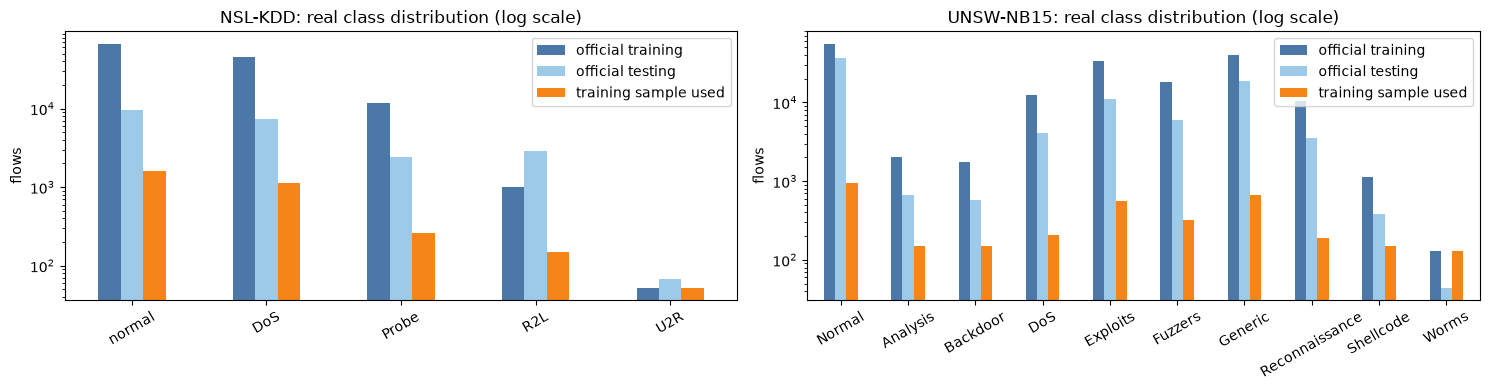

In [7]:
PALETTE = ["#4c78a8", "#e45756", "#f58518", "#54a24b", "#b279a2", "#72b7b2", "#9d755d", "#bab0ac", "#e377c2", "#17becf"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for k, (nm, s) in enumerate(SPEC.items()):
    cnt = pd.DataFrame({"official training": s["raw_tr"].cls.value_counts().reindex(s["classes"]),
                        "official testing": s["raw_te"].cls.value_counts().reindex(s["classes"]),
                        "training sample used": pd.Series(np.bincount(D[nm]["ytr"], minlength=D[nm]["n_classes"]), index=s["classes"])})
    cnt.plot.bar(ax=ax[k], rot=30, color=["#4c78a8", "#9ecae9", "#f58518"]); ax[k].set_yscale("log")
    ax[k].set_title(f"{nm}: real class distribution (log scale)"); ax[k].set_ylabel("flows")
plt.tight_layout(); plt.show()

NSL-KDD variance explained by the first 4 principal components: [0.484 0.201 0.069 0.053]


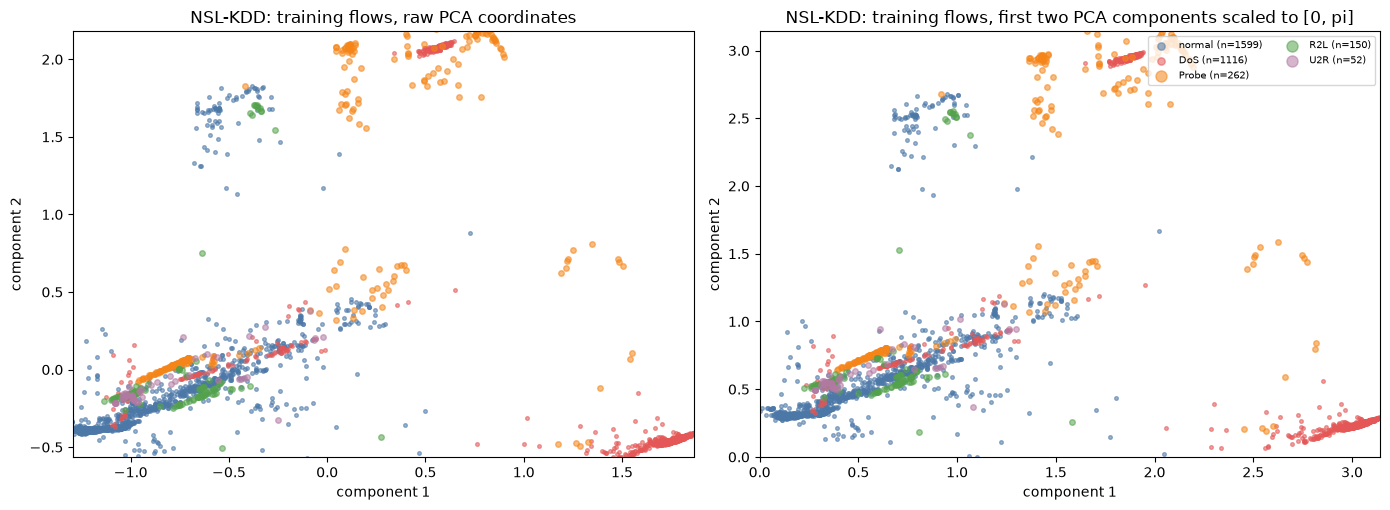

UNSW-NB15 variance explained by the first 4 principal components: [0.671 0.091 0.064 0.04 ]


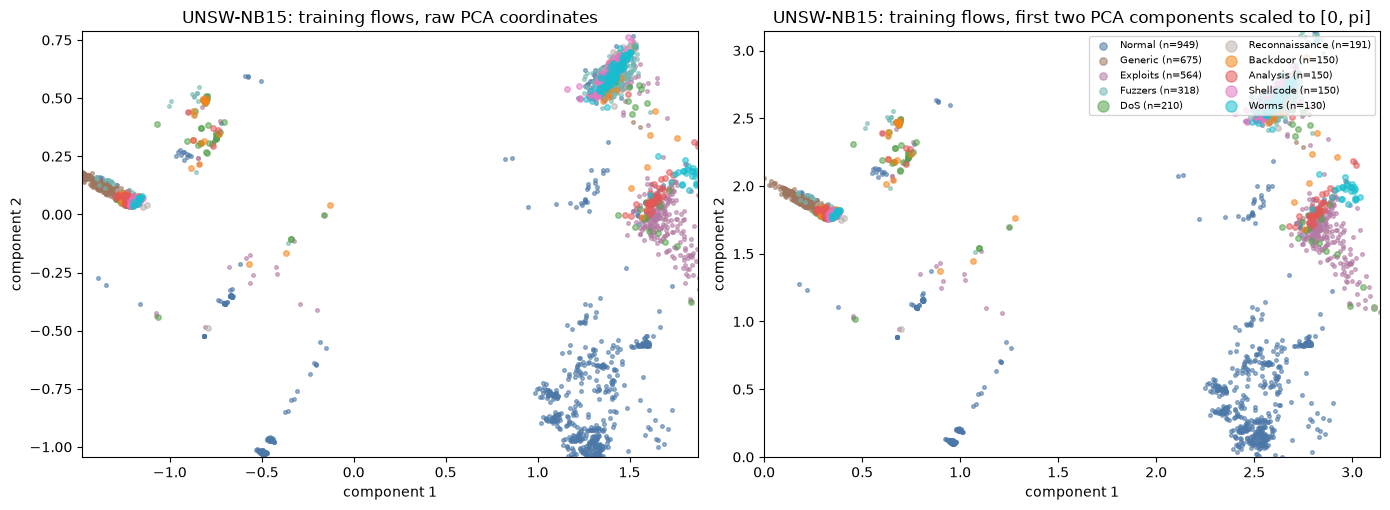

In [8]:
def pca_views(d, max_points=4000, seed=0):
    """Raw PCA coordinates fitted on the training sample, and the same coordinates scaled to [0, pi]."""
    pca = PCA(n_components=4, random_state=SEED).fit(d["Xtr"])
    Z = pca.transform(d["Xtr"]); mm = MinMaxScaler((0, np.pi)).fit(Z)
    A = np.clip(mm.transform(Z), 0, np.pi)
    r = np.random.default_rng(seed); sel = r.choice(len(Z), size=min(max_points, len(Z)), replace=False)
    return pca, Z[sel], A[sel], d["ytr"][sel]

def scatter(ax, P, y, classes, i, j, title, lim=None):
    for c in np.argsort(-np.bincount(y, minlength=len(classes))):        # big classes first, rare classes on top
        m = y == c
        if m.any(): ax.scatter(P[m, i], P[m, j], s=7 if m.sum() > 300 else 16, alpha=0.55, color=PALETTE[c], label=f"{classes[c]} (n={m.sum()})")
    ax.set_title(title); ax.set_xlabel(f"component {i+1}"); ax.set_ylabel(f"component {j+1}")
    if lim: ax.set_xlim(*lim); ax.set_ylim(*lim)

for nm, d in D.items():
    pca, Z, A, y = pca_views(d)
    print(nm, "variance explained by the first 4 principal components:", np.round(pca.explained_variance_ratio_, 3))
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
    scatter(ax[0], Z, y, d["classes"], 0, 1, f"{nm}: training flows, raw PCA coordinates")
    ax[0].set_xlim(*np.percentile(Z[:, 0], [0.5, 99.5])); ax[0].set_ylim(*np.percentile(Z[:, 1], [0.5, 99.5]))
    scatter(ax[1], A, y, d["classes"], 0, 1, f"{nm}: training flows, first two PCA components scaled to [0, pi]", lim=(0, np.pi))
    ax[1].legend(markerscale=2, fontsize=7, loc="upper right", ncol=2)
    plt.tight_layout(); plt.show()

## 3. The quantum convolution module

**Circuit (Section 3.2.2, Fig. 3, Table 4).** Four qubits start in $|0\rangle$. (1) Hadamard on every qubit gives $|+\rangle^{\otimes 4}$; (2) `RY(theta_i)` on qubit $i$ encodes the four angles; (3) one layer of PennyLane `RandomLayers`
(random single-qubit rotations RX/RY/RZ and a few CNOTs, parameters in $[0, 2\pi]$); (4) $\langle Z_i\rangle$ is measured on every qubit, giving $x_{quanv}\in\mathbb R^4$.

**Which angles?** The paper says only that the 448-dimensional classical vector is the input and that the angles are "generated by a quantum feature map". We use a trainable `Linear(448 -> 4)` followed by $\pi\tanh(\cdot)$.

**Which random layer?** `qml.RandomLayers(weights, wires, ratio_imprim=0.3, seed=42)` with 10 rotations. The gate pattern is fixed by the seed, the 10 angles are drawn once from $U[0,2\pi]$ and **not trained** (as in the PennyLane quanvolution tutorial,
where this layer comes from). Trainable quantum parameters: none; the trainable part of the module is the classical angle projection.

**How the simulation is done.** The reference object is a PennyLane QNode (`default.qubit`, PyTorch interface). Because the random-layer weights are fixed, the circuit after the encoding is one fixed unitary $U$, so the four read-outs are
$\langle Z_i\rangle=\psi(\theta)^{T}\,\mathrm{Re}(U^\dagger Z_i U)\,\psi(\theta)$ with the real product state $\psi(\theta)$ produced by H and RY. The notebook builds $U$ from PennyLane's own decomposition of `RandomLayers`
and asserts that this fast layer equals the QNode (values and gradients) to machine precision. Training then uses the fast layer (much quicker than calling the QNode inside the federated loops on a CPU).

In [9]:
# ---------------- reference circuit: a PennyLane QNode ----------------
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qconv_qnode(theta, weights):
    """The quantum convolution module of the paper: H -> RY(theta_i) -> RandomLayers -> <Z_i>."""
    for i in range(N_QUBITS): qml.Hadamard(wires=i)                                    # (1) Hadamard initialisation
    for i in range(N_QUBITS): qml.RY(theta[..., i], wires=i)                           # (2) RY angle encoding
    qml.RandomLayers(weights, wires=range(N_QUBITS), ratio_imprim=RL_RATIO, seed=RL_SEED)   # (3) one random layer
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]                       # (4) <Z_i> on every qubit

# ---------------- gate list of the random layer, taken from PennyLane's own decomposition ----------------
_sentinel = np.arange(RL_ROTATIONS, dtype=float).reshape(1, -1) + 1000.0       # recognise which weight each gate uses
def _rl(): qml.RandomLayers(_sentinel, wires=range(N_QUBITS), ratio_imprim=RL_RATIO, seed=RL_SEED)
RL_GATES = []
for op in qml.tape.make_qscript(_rl)().operations[0].decomposition():
    RL_GATES.append((op.name, tuple(op.wires.tolist()), int(round(float(op.parameters[0]) - 1000.0)) if op.parameters else None))
print("RandomLayers gate list (name, wires, weight index):")
for g in RL_GATES: print("  ", g)
print("qubits touched by a rotation:", sorted({g[1][0] for g in RL_GATES if g[0] != "CNOT"}), "| CNOTs:", [g[1] for g in RL_GATES if g[0] == "CNOT"])

# ---------------- fast exact layer: observables U^dagger Z_i U for the fixed random layer ----------------
DIM = 2 ** N_QUBITS
def _cnot_perm(c, t):
    perm = np.arange(DIM)
    for i in range(DIM):
        bits = [(i >> (N_QUBITS - 1 - k)) & 1 for k in range(N_QUBITS)]          # qubit 0 = most significant bit (PennyLane convention)
        if bits[c] == 1: bits[t] ^= 1
        perm[i] = sum(b << (N_QUBITS - 1 - k) for k, b in enumerate(bits))
    return torch.tensor(perm)
CNOT_PERM = {g[1]: _cnot_perm(*g[1]) for g in RL_GATES if g[0] == "CNOT"}
Z_SIGNS = torch.tensor([[1.0 - 2 * ((i >> (N_QUBITS - 1 - k)) & 1) for k in range(N_QUBITS)] for i in range(DIM)], dtype=torch.float64)   # (16, 4): eigenvalue of Z_k on basis state i

def _rot(name, a):
    c, s = math.cos(a / 2), math.sin(a / 2)
    if name == "RX": return torch.tensor([[c, -1j * s], [-1j * s, c]], dtype=torch.complex128)
    if name == "RY": return torch.tensor([[c, -s], [s, c]], dtype=torch.complex128)
    return torch.tensor([[np.exp(-0.5j * a), 0], [0, np.exp(0.5j * a)]], dtype=torch.complex128)    # RZ

def random_layer_unitary(weights):
    w = np.asarray(weights, dtype=float).reshape(-1)
    U = torch.eye(DIM, dtype=torch.complex128)
    for name, wires, idx in RL_GATES:
        if name == "CNOT":
            U = U[CNOT_PERM[wires], :]
        else:
            q = wires[0]
            U = torch.einsum("ij,ajc->aic", _rot(name, w[idx]), U.reshape(2 ** q, 2, 2 ** (N_QUBITS - q - 1) * DIM)).reshape(DIM, DIM)
    return U

def observable_matrices(weights, dtype=torch.float32):
    """Mcat (16, 64): column block k holds Re(U^dagger Z_k U); expectation_k = psi^T M_k psi for the real product state psi."""
    U = random_layer_unitary(weights)
    M = torch.stack([(U.conj().T @ torch.diag(Z_SIGNS[:, k]).to(torch.complex128) @ U).real for k in range(N_QUBITS)])
    return M.permute(1, 0, 2).reshape(DIM, N_QUBITS * DIM).to(dtype)

def quantum_layer(theta, Mcat):
    """theta (B, 4) -> (B, 4) expectation values. psi = (H then RY(theta_i)) |0> per qubit = [cos(t/2)-sin(t/2), cos(t/2)+sin(t/2)]/sqrt(2)."""
    B = theta.shape[0]; h = theta / 2
    v = torch.stack([torch.cos(h) - torch.sin(h), torch.cos(h) + torch.sin(h)], -1) / math.sqrt(2)     # (B, 4, 2)
    psi = v[:, 0, :]
    for q in range(1, N_QUBITS): psi = (psi[:, :, None] * v[:, q, None, :]).reshape(B, -1)             # (B, 16) product state
    return ((psi @ Mcat).reshape(B, N_QUBITS, DIM) * psi[:, None, :]).sum(-1)

# ---------------- equivalence check: fast layer == PennyLane QNode (values and gradients) ----------------
g = torch.Generator().manual_seed(SEED)
th_t = ((torch.rand(64, N_QUBITS, generator=g, dtype=torch.float64) * 2 - 1) * math.pi).requires_grad_(True)
w_t = torch.rand(1, RL_ROTATIONS, generator=g, dtype=torch.float64) * 2 * math.pi
ref = torch.stack(qconv_qnode(th_t, w_t), -1)
fast = quantum_layer(th_t, observable_matrices(w_t.numpy(), torch.float64))
g_ref = torch.autograd.grad(ref.sum(), th_t)[0]; g_fast = torch.autograd.grad(fast.sum(), th_t)[0]
print("max |QNode - fast layer|  :", float((ref - fast).abs().max()))
print("max |grad QNode - grad fast|:", float((g_ref - g_fast).abs().max()))
assert torch.allclose(ref, fast, atol=1e-10) and torch.allclose(g_ref, g_fast, atol=1e-10)
print("the fast training layer equals the PennyLane circuit.")

RandomLayers gate list (name, wires, weight index):
   ('RY', (1,), 0)
   ('RX', (2,), 1)
   ('CNOT', (1, 3), None)
   ('RZ', (2,), 2)
   ('RX', (2,), 3)
   ('RY', (3,), 4)
   ('RY', (2,), 5)
   ('CNOT', (1, 0), None)
   ('CNOT', (3, 2), None)
   ('RY', (2,), 6)
   ('RY', (1,), 7)
   ('RZ', (3,), 8)
   ('RX', (1,), 9)
qubits touched by a rotation: [1, 2, 3] | CNOTs: [(1, 3), (1, 0), (3, 2)]


max |QNode - fast layer|  : 9.992007221626409e-16
max |grad QNode - grad fast|: 1.7763568394002505e-15
the fast training layer equals the PennyLane circuit.


## Quantum Circuit Architecture

The circuit drawn below is the QNode `qconv_qnode` itself (with the angles of one example flow and the random-layer weights of one run). The first picture shows the module as written (`RandomLayers` as one box), the second the device-level circuit
after PennyLane expanded `RandomLayers` into the rotations and CNOTs that are actually executed. A cell then asserts that these executed gates are exactly the gate list used by the fast training layer, and prints qubit count, depth and parameter counts.
Assumptions where the paper omits details: the random-layer gate pattern (seed 42, ratio of CNOTs 0.3, 10 rotations) and the origin of the four angles (trained linear projection of the 448 classical features).

Matplotlib is building the font cache; this may take a moment.


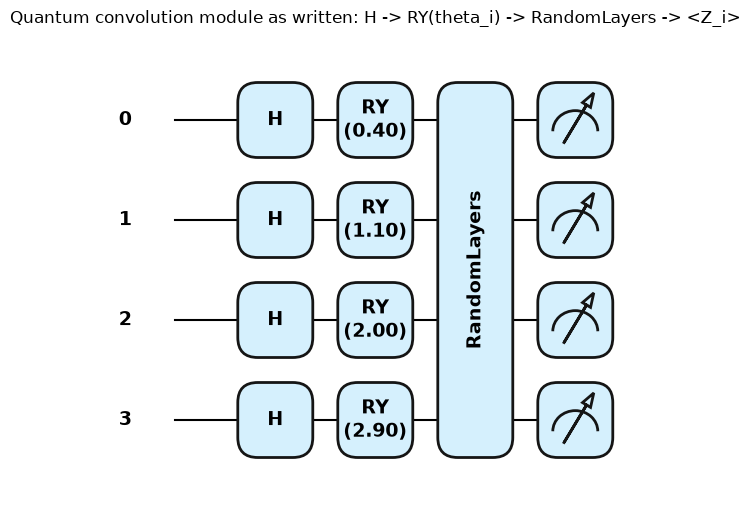

Matplotlib is building the font cache; this may take a moment.


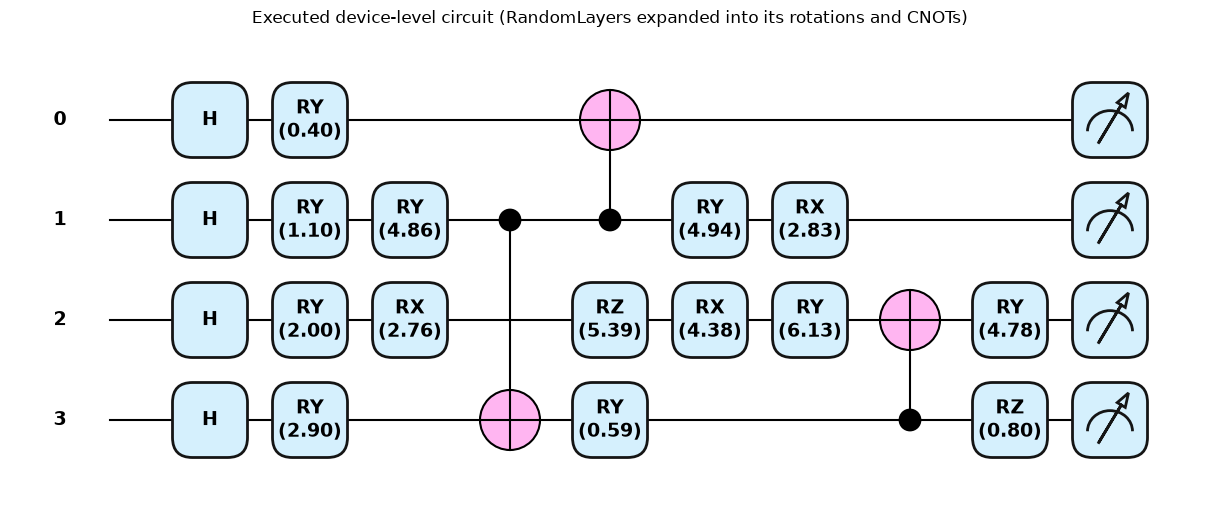

In [10]:
theta_demo = torch.tensor([0.4, 1.1, 2.0, 2.9], dtype=torch.float64)
w_demo = torch.tensor(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (1, RL_ROTATIONS)))
fig1, _ = qml.draw_mpl(qconv_qnode, decimals=2, style="pennylane")(theta_demo, w_demo)
fig1.suptitle("Quantum convolution module as written: H -> RY(theta_i) -> RandomLayers -> <Z_i>", y=1.02); plt.show()
fig2, _ = qml.draw_mpl(qconv_qnode, decimals=2, level="device", style="pennylane")(theta_demo, w_demo)
fig2.suptitle("Executed device-level circuit (RandomLayers expanded into its rotations and CNOTs)", y=1.02); plt.show()

In [11]:
tape = qml.workflow.construct_batch(qconv_qnode, level="device")(theta_demo, w_demo)[0][0]
ops = [(o.name, tuple(o.wires.tolist())) for o in tape.operations]
expected = [("Hadamard", (i,)) for i in range(N_QUBITS)] + [("RY", (i,)) for i in range(N_QUBITS)] + [(n, w) for n, w, _ in RL_GATES]
assert ops == expected, "executed circuit differs from the gate list of the fast layer"
print("assertion passed: the executed device circuit = 4 H + 4 RY (encoding) + the RandomLayers gate list used for training")

def circuit_depth(operations, n_wires):
    level = [0] * n_wires
    for o in operations:
        ws = list(o.wires); d = max(level[w] for w in ws) + 1
        for w in ws: level[w] = d
    return max(level)

n_rot = sum(1 for n, _ in ops if n in ("RX", "RY", "RZ")); n_cnot = sum(1 for n, _ in ops if n == "CNOT")
print("qubits                         :", N_QUBITS)
print("circuit depth (device level)   :", circuit_depth(tape.operations, N_QUBITS))
print("gates                          :", len(ops), f"({sum(1 for n,_ in ops if n=='Hadamard')} H, {n_rot} rotations incl. {N_QUBITS} encoding RY, {n_cnot} CNOT)")
print("circuit parameters             :", N_QUBITS, "encoding angles (computed from data by the trained Linear(448->4)) +", RL_ROTATIONS, "random-layer angles (fixed, drawn from U[0, 2 pi])")
print("trainable circuit parameters   : 0 (the random-layer weights are fixed; the trainable part is the classical Linear(448->4): %d parameters)" % (448 * 4 + 4))
print("measurements                   :", N_QUBITS, "Pauli-Z expectation values -> 4-dimensional quantum feature vector")

assertion passed: the executed device circuit = 4 H + 4 RY (encoding) + the RandomLayers gate list used for training
qubits                         : 4
circuit depth (device level)   : 8
gates                          : 21 (4 H, 14 rotations incl. 4 encoding RY, 3 CNOT)
circuit parameters             : 4 encoding angles (computed from data by the trained Linear(448->4)) + 10 random-layer angles (fixed, drawn from U[0, 2 pi])
trainable circuit parameters   : 0 (the random-layer weights are fixed; the trainable part is the classical Linear(448->4): 1796 parameters)
measurements                   : 4 Pauli-Z expectation values -> 4-dimensional quantum feature vector


## 4. The networks: FedCIDS, FedCQIDS and the classical control

* `cids`: Conv(3->32) + ReLU, Conv(32->64) + ReLU, flatten (896), FC1, FC2 (Table 3). Used as FedCIDS (federated) and CIDS (centralised).
* `cqids`: Conv(3->32) + ReLU, flatten (448), quantum convolution module (4 values), concatenate (448 + 4), FC1, FC2 (Table 4). Used as FedCQIDS and CQIDS.
* `control`: exactly `cqids`, but the circuit is replaced by `cos(angle)`, i.e. the same trainable 448->4 bottleneck with a classical nonlinearity. If FedCQIDS beats FedCIDS but not the control, the gain comes from the architecture, not from the quantum circuit.

In [12]:
class Net(nn.Module):
    def __init__(self, kind, hw, n_classes, fc1, q_weights=None):
        super().__init__()
        H, W = hw; self.kind = kind
        self.conv1 = nn.Conv2d(3, 32, 3, stride=1, padding=1)
        if kind == "cids":
            self.conv2 = nn.Conv2d(32, 64, 3, stride=1, padding=1); flat = H * W * 64          # 896
        else:
            flat = H * W * 32                                                                  # 448
            self.angles = nn.Linear(flat, N_QUBITS)                                            # CHOICE: how 448 features become 4 RY angles
            if kind == "cqids":
                self.register_buffer("Mcat", observable_matrices(q_weights, torch.float32), persistent=False)   # fixed random layer
            flat += N_QUBITS                                                                   # 448 + 4
        self.fc1 = nn.Linear(flat, fc1); self.fc2 = nn.Linear(fc1, n_classes)

    def quantum_features(self, h):
        theta = math.pi * torch.tanh(self.angles(h))
        return quantum_layer(theta, self.Mcat) if self.kind == "cqids" else torch.cos(theta)

    def forward(self, x):
        h = F.relu(self.conv1(x))
        if self.kind == "cids":
            h = F.relu(self.conv2(h)).flatten(1)
        else:
            h = h.flatten(1); h = torch.cat([h, self.quantum_features(h)], 1)
        return self.fc2(F.relu(self.fc1(h)))

def build_model(kind, d, seed):
    torch.manual_seed(1_000 + seed)
    qw = np.random.default_rng(2_000 + seed).uniform(0, 2 * np.pi, (1, RL_ROTATIONS))      # random-layer angles in [0, 2 pi], fixed per run
    return Net(kind, d["hw"], d["n_classes"], d["fc1"], qw)

for nm, d in D.items():
    for kind in ("cids", "cqids", "control"):
        m = build_model(kind, d, 0)
        print(f"{nm:10s} {kind:8s} trainable parameters: {sum(p.numel() for p in m.parameters()):,}   output for one batch: {tuple(m(d['Ttr'][:5]).shape)}")

NSL-KDD    cids     trainable parameters: 134,853   output for one batch: (5, 5)


NSL-KDD    cqids    trainable parameters: 61,321   output for one batch: (5, 5)
NSL-KDD    control  trainable parameters: 61,321   output for one batch: (5, 5)
UNSW-NB15  cids     trainable parameters: 48,426   output for one batch: (5, 10)
UNSW-NB15  cqids    trainable parameters: 17,518   output for one batch: (5, 10)


UNSW-NB15  control  trainable parameters: 17,518   output for one batch: (5, 10)


## 5. Federated training (FedAvg) and centralised training

Per round: the server sends the global weights to each client; the client trains `LOCAL_EPOCHS` epochs of mini-batch Adam (`BATCH`, `LR`; fresh optimiser state) on its shard; the server replaces the global weights by the average of the clients' weights
weighted by shard size; the global model is then evaluated on the test set (accuracy, cross-entropy, confusion matrix). The reference implementation trains the clients one after the other; the production path trains the K clients as one stacked network (exactly equivalent, verified below) because tensor-operation overhead, not arithmetic, dominates for such small networks. The centralised baselines train one model on the pooled sample for `CENTRAL_EPOCHS` epochs and are evaluated after each epoch.

In [13]:
@torch.no_grad()
def evaluate(model, X, y, n_classes, bs=8192):
    model.eval(); losses, preds = [], []
    for i in range(0, len(y), bs):
        out = model(X[i:i + bs]); losses.append(F.cross_entropy(out, y[i:i + bs], reduction="sum").item()); preds.append(out.argmax(1))
    pred = torch.cat(preds).numpy(); yt = y.numpy()
    cm = confusion_matrix(yt, pred, labels=list(range(n_classes)))
    return float((pred == yt).mean()), float(sum(losses) / len(yt)), cm

def make_perms(seed, rnd, k, n, epochs):
    """Mini-batch order of client k in round rnd: one random permutation of its shard per local epoch (reproducible, independent of the code path)."""
    g = torch.Generator().manual_seed(1_000_003 * (seed + 1) + 1_009 * rnd + k)
    return [torch.randperm(n, generator=g) for _ in range(epochs)]

def local_train(model, X, y, perms):
    """Reference implementation: train ONE client model with Adam (fresh state) on mini-batches of BATCH rows in the given orders."""
    opt = torch.optim.Adam(model.parameters(), lr=LR); model.train()
    for perm in perms:
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad(); F.cross_entropy(model(X[idx]), y[idx]).backward(); opt.step()

def iid_shards(n, k, rng):
    return np.array_split(rng.permutation(n), k)

def dirichlet_shards(labels, k, alpha, rng, min_size=20):
    while True:
        parts = [[] for _ in range(k)]
        for c in np.unique(labels):
            idx = np.where(labels == c)[0]; rng.shuffle(idx)
            p = rng.dirichlet(alpha * np.ones(k)); cuts = (np.cumsum(p) * len(idx)).astype(int)[:-1]
            for i, chunk in enumerate(np.split(idx, cuts)): parts[i] += chunk.tolist()
        if min(len(p) for p in parts) >= min_size: return [np.array(p) for p in parts]

def summarize(rec):
    return dict(max=max(rec["acc"]), mean=float(np.mean(rec["acc"])), last=rec["acc"][-1], loss_mean=float(np.mean(rec["loss"])))

# ---- vectorised simulation of the K clients (identical maths, ~K times fewer tensor operations) ----
# All K client models are stored as stacked tensors (K, ...). Convolutions use groups=K, linear layers use bmm. Because Adam acts element-wise
# and the loss is the SUM of the K per-client mean losses, every client receives exactly its own gradient and its own Adam update.
def stacked_forward(kind, P, Mcat, x):
    """x: (K, b, 3, H, W) -> logits (K, b, n_classes) for K independent client models with parameters P[name] of shape (K, ...)."""
    K, b, _, H, W = x.shape
    h = x.permute(1, 0, 2, 3, 4).reshape(b, K * 3, H, W)
    h = F.relu(F.conv2d(h, P["conv1.weight"].reshape(K * 32, 3, 3, 3), P["conv1.bias"].reshape(-1), padding=1, groups=K))
    if kind == "cids":
        h = F.relu(F.conv2d(h, P["conv2.weight"].reshape(K * 64, 32, 3, 3), P["conv2.bias"].reshape(-1), padding=1, groups=K))
        h = h.reshape(b, K, -1).permute(1, 0, 2)                                                  # (K, b, H*W*64)
    else:
        h = h.reshape(b, K, -1).permute(1, 0, 2)                                                  # (K, b, H*W*32)
        theta = math.pi * torch.tanh(torch.baddbmm(P["angles.bias"][:, None, :], h, P["angles.weight"].transpose(1, 2)))     # (K, b, 4)
        q = quantum_layer(theta.reshape(K * b, N_QUBITS), Mcat).reshape(K, b, N_QUBITS) if kind == "cqids" else torch.cos(theta)
        h = torch.cat([h, q], -1)
    h = F.relu(torch.baddbmm(P["fc1.bias"][:, None, :], h, P["fc1.weight"].transpose(1, 2)))
    return torch.baddbmm(P["fc2.bias"][:, None, :], h, P["fc2.weight"].transpose(1, 2))

def local_train_stacked(kind, gstate, Mcat, X, Y, perms):
    """X: (K, n, 3, H, W), Y: (K, n), perms[k][e] = order of client k in local epoch e. Returns the K trained parameter sets, stacked."""
    K, n = Y.shape; ar = torch.arange(K)[:, None]
    P = {name: nn.Parameter(v.unsqueeze(0).repeat(K, *([1] * v.dim()))) for name, v in gstate.items()}
    opt = torch.optim.Adam(list(P.values()), lr=LR)
    for e in range(len(perms[0])):
        order = torch.stack([perms[k][e] for k in range(K)])                                    # (K, n)
        for i in range(0, n, BATCH):
            idx = order[:, i:i + BATCH]
            out = stacked_forward(kind, P, Mcat, X[ar, idx]); yb = Y[ar, idx]
            loss = F.cross_entropy(out.reshape(-1, out.shape[-1]), yb.reshape(-1), reduction="none").reshape(K, -1).mean(1).sum()
            opt.zero_grad(); loss.backward(); opt.step()
    return {name: p.detach() for name, p in P.items()}

def run_federated(kind, d, seed, partition="iid", rounds=None, local_epochs=None, vectorised=True):
    rounds = rounds or ROUNDS; local_epochs = local_epochs or LOCAL_EPOCHS
    rng = np.random.default_rng(4_000 + seed)
    if partition == "iid":                      # equal shards of N // K rows (the <= 9 left-over rows are dropped, so that all clients can be simulated as one stacked model)
        n_k = len(d["ytr"]) // N_CLIENTS; parts = list(rng.permutation(len(d["ytr"]))[:N_CLIENTS * n_k].reshape(N_CLIENTS, n_k))
    else:
        parts = dirichlet_shards(d["ytr"], N_CLIENTS, DIRICHLET_ALPHA, rng); vectorised = False      # unequal shard sizes: use the reference loop
    sizes = np.array([len(p) for p in parts]); wts = sizes / sizes.sum()
    gmodel, lmodel = build_model(kind, d, seed), build_model(kind, d, seed)
    rec = dict(acc=[], loss=[], cms=[], sizes=sizes.tolist(), kind=kind, partition=partition)
    if vectorised:
        Xs = torch.stack([d["Ttr"][p] for p in parts]); Ys = torch.stack([d["Ytr"][p] for p in parts])
    t0 = time.time()
    for r in range(rounds):
        gstate = {k: v.clone() for k, v in gmodel.state_dict().items()}
        perms = [make_perms(seed, r, k, len(parts[k]), local_epochs) for k in range(N_CLIENTS)]
        if vectorised:
            st = local_train_stacked(kind, gstate, getattr(gmodel, "Mcat", None), Xs, Ys, perms)
            agg = {k: (torch.tensor(wts, dtype=v.dtype).reshape(-1, *([1] * (v.dim() - 1))) * v).sum(0) for k, v in st.items()}      # FedAvg: weighted by shard size
        else:
            agg = None
            for k, p in enumerate(parts):
                lmodel.load_state_dict(gstate); local_train(lmodel, d["Ttr"][p], d["Ytr"][p], perms[k]); sd = lmodel.state_dict()
                agg = {n: float(wts[k]) * v.clone() for n, v in sd.items()} if agg is None else {n: agg[n] + float(wts[k]) * sd[n] for n in agg}
        gmodel.load_state_dict(agg)
        acc, loss, cm = evaluate(gmodel, d["Tte"], d["Yte"], d["n_classes"])
        rec["acc"].append(acc); rec["loss"].append(loss); rec["cms"].append(cm)
    rec["time"] = time.time() - t0; rec["model"] = gmodel
    return rec

def run_centralised(kind, d, seed, epochs=None):
    epochs = epochs or CENTRAL_EPOCHS
    gen = torch.Generator().manual_seed(5_000 + seed); model = build_model(kind, d, seed)
    rec = dict(acc=[], loss=[], cms=[], kind=kind); t0 = time.time()
    for e in range(epochs):
        local_train(model, d["Ttr"], d["Ytr"], [torch.randperm(len(d["Ytr"]), generator=gen)])
        acc, loss, cm = evaluate(model, d["Tte"], d["Yte"], d["n_classes"])
        rec["acc"].append(acc); rec["loss"].append(loss); rec["cms"].append(cm)
    rec["time"] = time.time() - t0; rec["model"] = model
    return rec

# ---- check: the stacked (vectorised) clients do exactly what K separate clients do (float64, 2 local epochs, 3 clients) ----
def check_stacked(kind, d, K=3, n=70, epochs=2):
    m = build_model(kind, d, 0).double(); gstate = {k: v.clone() for k, v in m.state_dict().items()}
    Mc = getattr(m, "Mcat", None)
    X = d["Ttr"][:K * n].double().reshape(K, n, *d["Ttr"].shape[1:]); Y = d["Ytr"][:K * n].reshape(K, n)
    perms = [make_perms(0, 0, k, n, epochs) for k in range(K)]
    st = local_train_stacked(kind, gstate, Mc, X, Y, perms)
    worst = 0.0
    for k in range(K):
        lm = build_model(kind, d, 0).double(); lm.load_state_dict(gstate); local_train(lm, X[k], Y[k], perms[k])
        worst = max(worst, max(float((v - st[name][k]).abs().max()) for name, v in lm.state_dict().items()))
    return worst
for _kind in ("cids", "cqids", "control"):
    w = check_stacked(_kind, D["UNSW-NB15"])
    print(f"stacked clients vs {3} separate clients, model {_kind:8s}: max |difference| of the trained weights = {w:.2e}")
    assert w < 1e-8
print("the vectorised federation is numerically the same as the plain per-client loop.")

RES = {}     # (dataset, model name, seed) -> record
NAMES = {"fed": {"cids": "FedCIDS", "cqids": "FedCQIDS", "control": "FedCQIDS-control"}, "cen": {"cids": "CIDS", "cqids": "CQIDS"}}
# quick smoke test of the machinery (one round, one local epoch on the first shard) before the long runs
_t = time.time(); _r = run_federated("cqids", D["NSL-KDD"], 0, rounds=1, local_epochs=1)
print(f"smoke test: 1 round x 1 local epoch of FedCQIDS on NSL-KDD took {time.time() - _t:.1f} s, accuracy {_r['acc'][0]:.3f}")

stacked clients vs 3 separate clients, model cids    : max |difference| of the trained weights = 2.78e-17


stacked clients vs 3 separate clients, model cqids   : max |difference| of the trained weights = 1.18e-16


stacked clients vs 3 separate clients, model control : max |difference| of the trained weights = 3.47e-17
the vectorised federation is numerically the same as the plain per-client loop.


smoke test: 1 round x 1 local epoch of FedCQIDS on NSL-KDD took 3.5 s, accuracy 0.497


### 5.1 Run: NSL-KDD

Models per seed: FedCIDS, FedCQIDS, FedCQIDS-control (federated, IID shards), CIDS and CQIDS (centralised). The accuracy of every round is stored.

In [14]:
ds_name = "NSL-KDD"
for seed in SEEDS:
    d = make_dataset(ds_name, seed)
    shard_sizes = None
    for kind in ["cids", "cqids"] + (["control"] if RUN_CONTROL else []):
        rec = run_federated(kind, d, seed); RES[(ds_name, NAMES["fed"][kind], seed)] = rec; s = summarize(rec)
        print(f"{ds_name} seed {seed} {NAMES['fed'][kind]:17s} max {100*s['max']:.2f} | mean {100*s['mean']:.2f} | last {100*s['last']:.2f} | mean loss {s['loss_mean']:.4f} | {rec['time']:.0f} s")
    for kind in ["cids", "cqids"]:
        rec = run_centralised(kind, d, seed); RES[(ds_name, NAMES["cen"][kind], seed)] = rec; s = summarize(rec)
        print(f"{ds_name} seed {seed} {NAMES['cen'][kind]:17s} max {100*s['max']:.2f} | mean {100*s['mean']:.2f} | last {100*s['last']:.2f} | mean loss {s['loss_mean']:.4f} | {rec['time']:.0f} s")
print("shard sizes of the last federation:", RES[(ds_name, "FedCIDS", SEEDS[-1])]["sizes"])

NSL-KDD seed 0 FedCIDS           max 77.79 | mean 76.53 | last 76.94 | mean loss 1.8570 | 668 s


NSL-KDD seed 0 FedCQIDS          max 78.70 | mean 77.14 | last 78.61 | mean loss 1.7056 | 183 s


NSL-KDD seed 0 FedCQIDS-control  max 76.57 | mean 75.54 | last 76.57 | mean loss 1.6761 | 74 s


NSL-KDD seed 0 CIDS              max 81.99 | mean 76.98 | last 78.68 | mean loss 1.5193 | 53 s


NSL-KDD seed 0 CQIDS             max 81.13 | mean 76.97 | last 77.61 | mean loss 1.2989 | 49 s


NSL-KDD seed 1 FedCIDS           max 79.38 | mean 77.96 | last 79.24 | mean loss 1.7764 | 550 s


NSL-KDD seed 1 FedCQIDS          max 78.29 | mean 77.23 | last 78.14 | mean loss 1.5727 | 178 s


NSL-KDD seed 1 FedCQIDS-control  max 78.60 | mean 77.15 | last 78.52 | mean loss 1.5924 | 156 s


NSL-KDD seed 1 CIDS              max 78.81 | mean 76.69 | last 76.84 | mean loss 1.5324 | 88 s


NSL-KDD seed 1 CQIDS             max 79.42 | mean 76.77 | last 78.65 | mean loss 1.2599 | 52 s
shard sizes of the last federation: [317, 317, 317, 317, 317, 317, 317, 317, 317, 317]


### 5.2 Run: UNSW-NB15

In [15]:
ds_name = "UNSW-NB15"
for seed in SEEDS:
    d = make_dataset(ds_name, seed)
    shard_sizes = None
    for kind in ["cids", "cqids"] + (["control"] if RUN_CONTROL else []):
        rec = run_federated(kind, d, seed); RES[(ds_name, NAMES["fed"][kind], seed)] = rec; s = summarize(rec)
        print(f"{ds_name} seed {seed} {NAMES['fed'][kind]:17s} max {100*s['max']:.2f} | mean {100*s['mean']:.2f} | last {100*s['last']:.2f} | mean loss {s['loss_mean']:.4f} | {rec['time']:.0f} s")
    for kind in ["cids", "cqids"]:
        rec = run_centralised(kind, d, seed); RES[(ds_name, NAMES["cen"][kind], seed)] = rec; s = summarize(rec)
        print(f"{ds_name} seed {seed} {NAMES['cen'][kind]:17s} max {100*s['max']:.2f} | mean {100*s['mean']:.2f} | last {100*s['last']:.2f} | mean loss {s['loss_mean']:.4f} | {rec['time']:.0f} s")
print("shard sizes of the last federation:", RES[(ds_name, "FedCIDS", SEEDS[-1])]["sizes"])

UNSW-NB15 seed 0 FedCIDS           max 62.78 | mean 59.86 | last 61.69 | mean loss 1.0245 | 539 s


UNSW-NB15 seed 0 FedCQIDS          max 64.98 | mean 60.71 | last 64.41 | mean loss 1.0217 | 188 s


UNSW-NB15 seed 0 FedCQIDS-control  max 67.16 | mean 62.66 | last 67.16 | mean loss 0.9905 | 145 s


UNSW-NB15 seed 0 CIDS              max 65.72 | mean 62.09 | last 65.72 | mean loss 0.9625 | 212 s


UNSW-NB15 seed 0 CQIDS             max 65.76 | mean 59.89 | last 63.07 | mean loss 1.0388 | 82 s


UNSW-NB15 seed 1 FedCIDS           max 65.04 | mean 62.94 | last 65.04 | mean loss 0.9479 | 444 s


UNSW-NB15 seed 1 FedCQIDS          max 66.48 | mean 62.69 | last 66.06 | mean loss 0.9529 | 179 s


UNSW-NB15 seed 1 FedCQIDS-control  max 64.86 | mean 62.07 | last 64.86 | mean loss 0.9891 | 200 s


UNSW-NB15 seed 1 CIDS              max 66.19 | mean 63.07 | last 65.50 | mean loss 0.9449 | 219 s


UNSW-NB15 seed 1 CQIDS             max 68.84 | mean 62.85 | last 64.84 | mean loss 0.9519 | 91 s
shard sizes of the last federation: [350, 350, 350, 350, 350, 350, 350, 350, 350, 350]


## 6. Classical baselines on the identical inputs

RandomForest and an RBF-SVM are trained on exactly the same 42 preprocessed inputs of the same training sample (centralised, no federation) and evaluated on the same test rows.

In [16]:
BASE = {}
for nm in SPEC:
    for seed in SEEDS:
        d = make_dataset(nm, seed); t0 = time.time()
        rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(d["Xtr"], d["ytr"])
        BASE[(nm, "RandomForest", seed)] = (accuracy_score(d["yte"], rf.predict(d["Xte"])), time.time() - t0)
        sub = np.random.default_rng(seed).choice(len(d["ytr"]), size=min(SVC_MAX_TRAIN, len(d["ytr"])), replace=False)
        t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(d["Xtr"][sub], d["ytr"][sub])
        BASE[(nm, "SVC(rbf)", seed)] = (accuracy_score(d["yte"], svc.predict(d["Xte"])), time.time() - t0)
base_tab = pd.DataFrame([(k[0], k[1], k[2], round(100 * v[0], 2), round(v[1], 1)) for k, v in BASE.items()], columns=["dataset", "model", "seed", "test accuracy %", "fit+predict s"])
display(base_tab.groupby(["dataset", "model"])[["test accuracy %", "fit+predict s"]].mean().round(2))

test accuracy %  fit+predict s
dataset   model                                       
NSL-KDD   RandomForest            75.87           3.50
          SVC(rbf)                75.40           8.05
UNSW-NB15 RandomForest            72.13           9.10
          SVC(rbf)                61.04         116.45

## 7. Extra: non-IID clients (Dirichlet shards)

The paper says the data are "distributed and heterogeneous" but does not describe the partition. As an ablation, each class is split over the 10 clients with Dirichlet($\alpha$) proportions (every client keeps at least 20 rows); FedCIDS and FedCQIDS are trained on these skewed shards (first seed only).
Skipped in FAST_MODE.

In [17]:
NONIID = {}
if RUN_NONIID:
    for nm in SPEC:
        d = make_dataset(nm, SEEDS[0])
        for kind in ("cids", "cqids"):
            rec = run_federated(kind, d, SEEDS[0], partition="dirichlet"); NONIID[(nm, NAMES["fed"][kind])] = rec; s = summarize(rec)
            print(f"{nm} non-IID {NAMES['fed'][kind]:10s} max {100*s['max']:.2f} | mean {100*s['mean']:.2f} | last {100*s['last']:.2f} | {rec['time']:.0f} s | shard sizes {rec['sizes']}")
else:
    print("RUN_NONIID is False (FAST_MODE): skipped")

RUN_NONIID is False (FAST_MODE): skipped


## 8. Results: curves (re-drawing Figs. 4 and 5) and tables

Accuracy and cross-entropy of the global model after every communication round, mean over seeds with the seed range shaded (one seed in FAST_MODE). The paper shows only FedCIDS and FedCQIDS; the classical control is added.

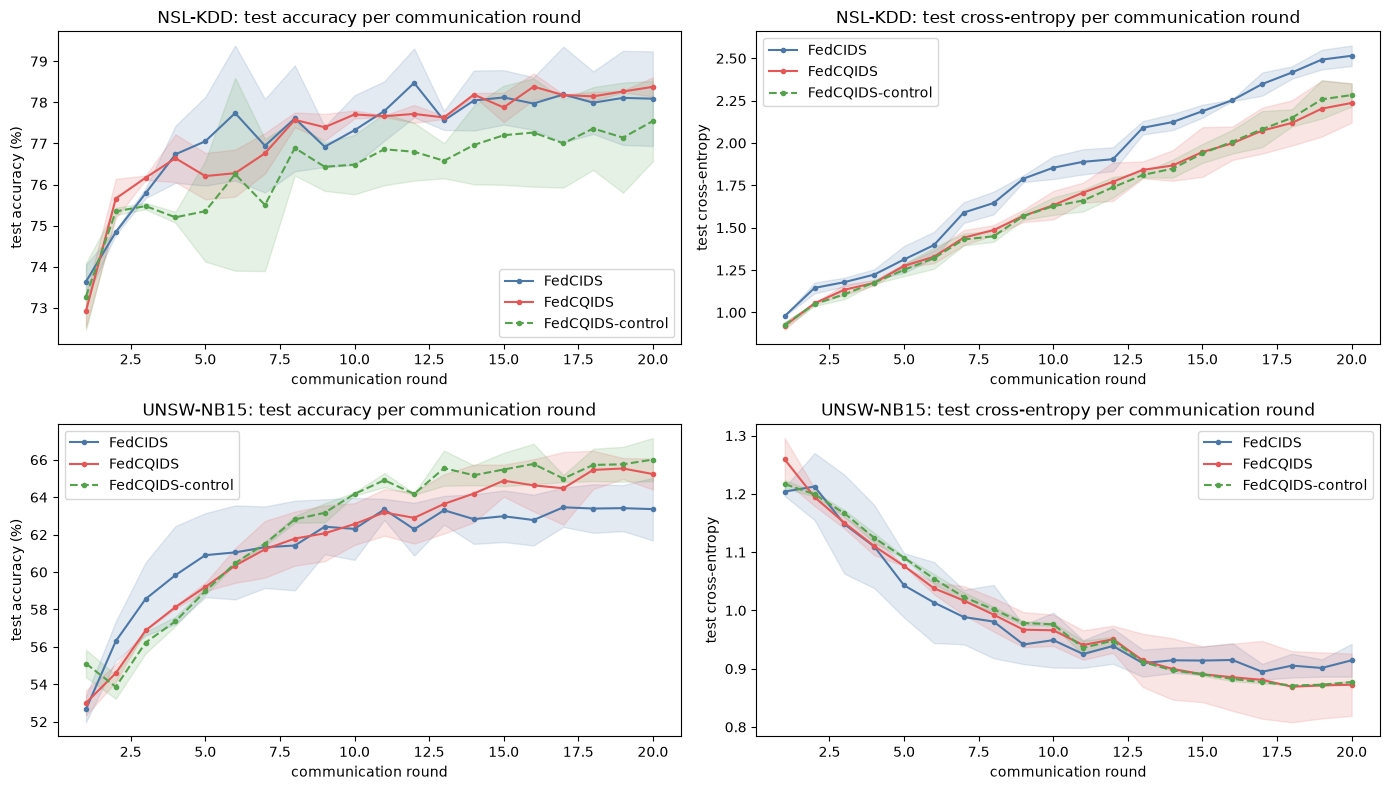

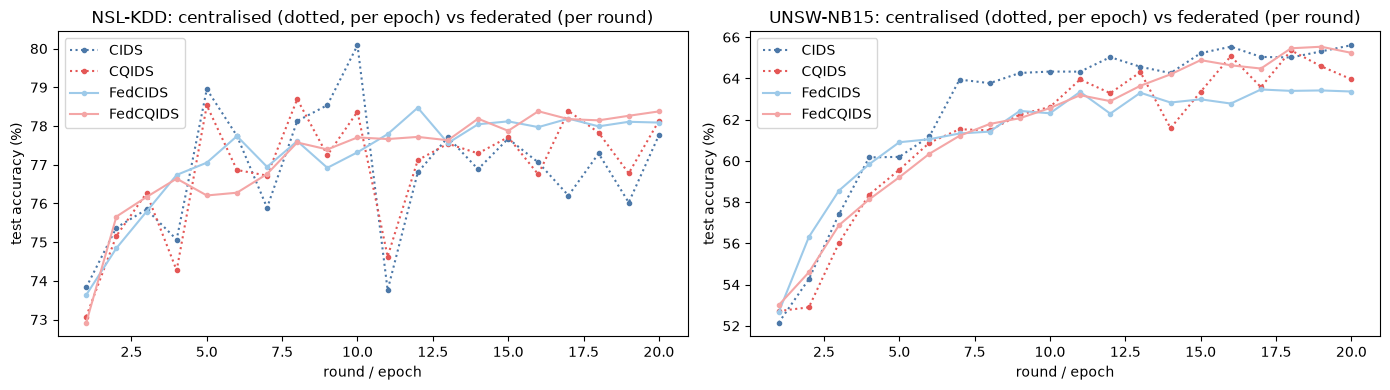

In [18]:
def stack(ds, name, key):
    return np.array([RES[(ds, name, s)][key] for s in SEEDS])

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for r, ds in enumerate(SPEC):
    for c, (key, lab) in enumerate([("acc", "test accuracy"), ("loss", "test cross-entropy")]):
        for name, col in [("FedCIDS", "#4c78a8"), ("FedCQIDS", "#e45756"), ("FedCQIDS-control", "#54a24b")]:
            if (ds, name, SEEDS[0]) not in RES: continue
            A = stack(ds, name, key) * (100 if key == "acc" else 1); x = np.arange(1, A.shape[1] + 1)
            ax[r, c].plot(x, A.mean(0), marker="o", ms=3, color=col, label=name, ls="--" if "control" in name else "-")
            if len(SEEDS) > 1: ax[r, c].fill_between(x, A.min(0), A.max(0), color=col, alpha=0.15)
        ax[r, c].set_title(f"{ds}: {lab} per communication round"); ax[r, c].set_xlabel("communication round"); ax[r, c].set_ylabel(lab + (" (%)" if key == "acc" else ""))
        ax[r, c].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, ds in enumerate(SPEC):
    for name, col in [("CIDS", "#4c78a8"), ("CQIDS", "#e45756"), ("FedCIDS", "#9ecae9"), ("FedCQIDS", "#f4a6a6")]:
        A = stack(ds, name, "acc") * 100; ax[k].plot(np.arange(1, A.shape[1] + 1), A.mean(0), marker="o", ms=3, label=name, color=col, ls="-" if name.startswith("Fed") else ":")
    ax[k].set_title(f"{ds}: centralised (dotted, per epoch) vs federated (per round)"); ax[k].set_xlabel("round / epoch"); ax[k].set_ylabel("test accuracy (%)"); ax[k].legend()
plt.tight_layout(); plt.show()

In [19]:
MODELS = ["CIDS", "CQIDS", "FedCIDS", "FedCQIDS", "FedCQIDS-control"]
def agg(ds, name, fn):
    v = np.array([fn(summarize(RES[(ds, name, s)])) for s in SEEDS]); return v.mean(), v.std()

rows = []
for ds in SPEC:
    for name in MODELS:
        if (ds, name, SEEDS[0]) not in RES: continue
        mx, sx = agg(ds, name, lambda s: 100 * s["max"]); mn, sn = agg(ds, name, lambda s: 100 * s["mean"]); la, sl = agg(ds, name, lambda s: 100 * s["last"]); lo, _ = agg(ds, name, lambda s: s["loss_mean"])
        rows.append(dict(dataset=ds, model=name, **{"max acc %": f"{mx:.2f} ± {sx:.2f}", "mean acc over rounds %": f"{mn:.2f} ± {sn:.2f}", "last-round acc %": f"{la:.2f} ± {sl:.2f}", "mean test CE": round(lo, 4)}))
res_table = pd.DataFrame(rows); display(res_table)
print(f"({len(SEEDS)} seed(s): mean ± std over seeds; 'max acc' is the paper's Table 5 definition and is selected on the test set, hence optimistic)")

,dataset,model,max acc %,mean acc over rounds %,last-round acc %,mean test CE
0,NSL-KDD,CIDS,80.40 ± 1.59,76.83 ± 0.14,77.76 ± 0.92,1.5258
1,NSL-KDD,CQIDS,80.28 ± 0.86,76.87 ± 0.10,78.13 ± 0.52,1.2794
2,NSL-KDD,FedCIDS,78.59 ± 0.80,77.25 ± 0.71,78.09 ± 1.15,1.8167
3,NSL-KDD,FedCQIDS,78.50 ± 0.21,77.19 ± 0.05,78.38 ± 0.23,1.6391
4,NSL-KDD,FedCQIDS-control,77.58 ± 1.01,76.35 ± 0.81,77.55 ± 0.98,1.6342
5,UNSW-NB15,CIDS,65.96 ± 0.24,62.58 ± 0.49,65.61 ± 0.11,0.9537
6,UNSW-NB15,CQIDS,67.30 ± 1.54,61.37 ± 1.48,63.96 ± 0.88,0.9954
7,UNSW-NB15,FedCIDS,63.91 ± 1.13,61.40 ± 1.54,63.36 ± 1.67,0.9862
8,UNSW-NB15,FedCQIDS,65.73 ± 0.75,61.70 ± 0.99,65.24 ± 0.83,0.9873
9,UNSW-NB15,FedCQIDS-control,66.01 ± 1.15,62.36 ± 0.29,66.01 ± 1.15,0.9898


(2 seed(s): mean ± std over seeds; 'max acc' is the paper's Table 5 definition and is selected on the test set, hence optimistic)


### 8.1 Per-class accuracy (re-drawing Table 6) and confusion matrices

Table 6 reports the detection accuracy (recall) of the two rarest UNSW-NB15 attack classes. Recall is read from the confusion matrix of the global model: last round, and mean over the last five rounds (the paper does not say which round it used).

,class,test flows here,paper test flows,model,recall last round %,recall mean of last 5 rounds %
0,Shellcode,378,378,FedCIDS,73.9 ± 0.9,70.8 ± 1.2
1,Shellcode,378,378,FedCQIDS,78.6 ± 1.6,72.0 ± 0.2
2,Shellcode,378,378,FedCQIDS-control,72.9 ± 7.8,69.6 ± 4.0
3,Worms,44,44,FedCIDS,73.9 ± 1.1,73.2 ± 1.4
4,Worms,44,44,FedCQIDS,65.9 ± 0.0,63.9 ± 0.7
5,Worms,44,44,FedCQIDS-control,67.0 ± 5.7,64.3 ± 6.6


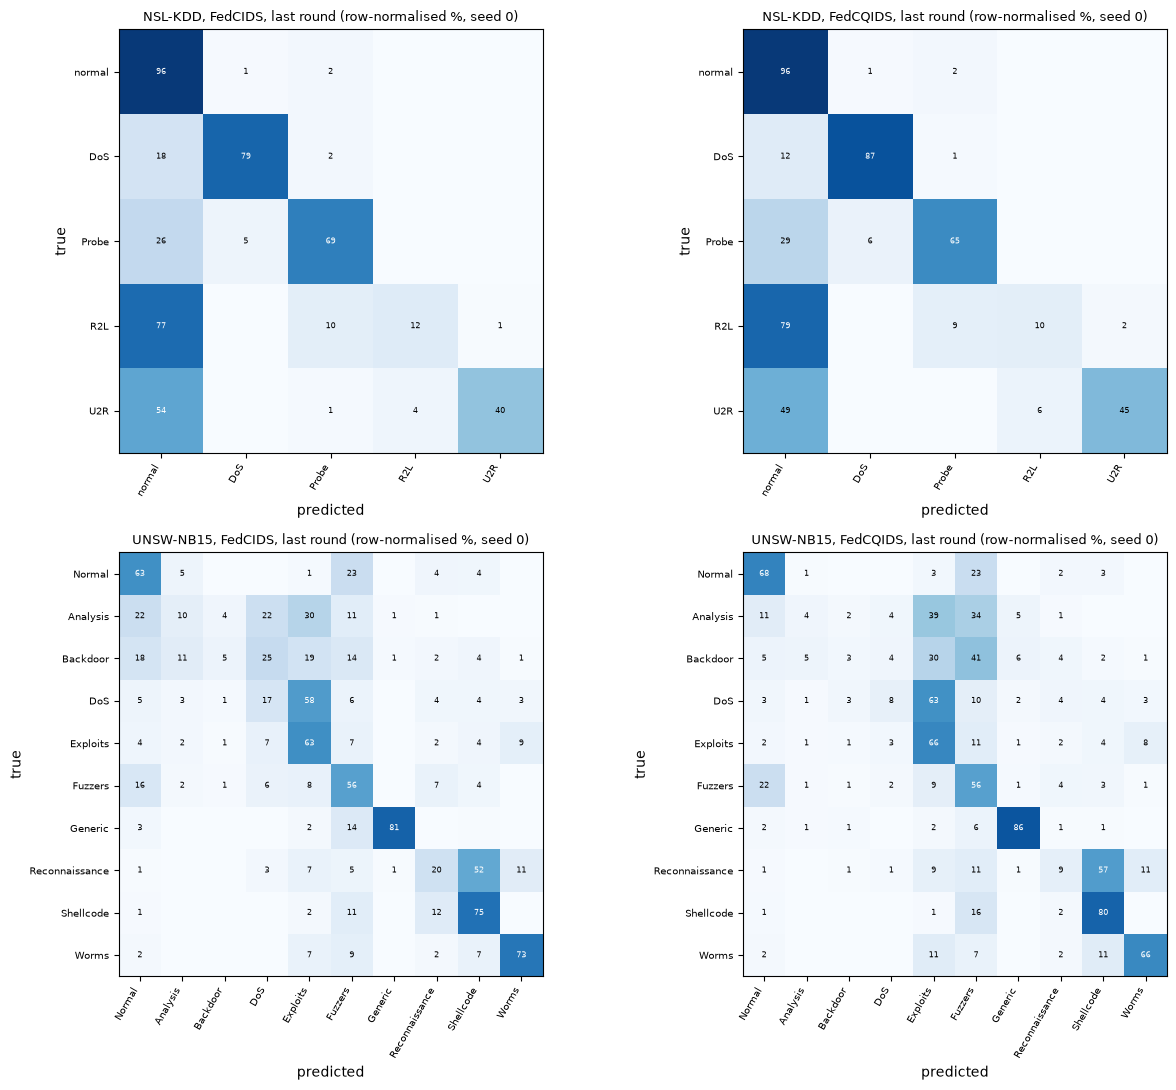

In [20]:
def recall_last(ds, name, cls, last_k=1):
    ci = SPEC[ds]["classes"].index(cls); vals = []
    for s in SEEDS:
        cms = RES[(ds, name, s)]["cms"][-last_k:]; vals.append(np.mean([cm[ci, ci] / max(cm[ci].sum(), 1) for cm in cms]))
    return 100 * np.mean(vals), 100 * np.std(vals)

t6 = []
for cls, n_paper in [("Shellcode", 378), ("Worms", 44)]:
    n_test = int((D["UNSW-NB15"]["yte"] == SPEC["UNSW-NB15"]["classes"].index(cls)).sum())
    for name in ["FedCIDS", "FedCQIDS", "FedCQIDS-control"]:
        if ("UNSW-NB15", name, SEEDS[0]) not in RES: continue
        l1 = recall_last("UNSW-NB15", name, cls, 1); l5 = recall_last("UNSW-NB15", name, cls, min(5, ROUNDS))
        t6.append({"class": cls, "test flows here": n_test, "paper test flows": n_paper, "model": name, "recall last round %": f"{l1[0]:.1f} ± {l1[1]:.1f}", f"recall mean of last {min(5, ROUNDS)} rounds %": f"{l5[0]:.1f} ± {l5[1]:.1f}"})
display(pd.DataFrame(t6))

def show_cm(ax, cm, classes, title):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=60, ha="right", fontsize=7); ax.set_yticklabels(classes, fontsize=7); ax.set_title(title, fontsize=9)
    for i in range(len(classes)):
        for j in range(len(classes)):
            if cmn[i, j] > 0.005: ax.text(j, i, f"{100*cmn[i,j]:.0f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig, ax = plt.subplots(2, 2, figsize=(13, 11))
for r, ds in enumerate(SPEC):
    for c, name in enumerate(["FedCIDS", "FedCQIDS"]):
        show_cm(ax[r, c], RES[(ds, name, SEEDS[0])]["cms"][-1], SPEC[ds]["classes"], f"{ds}, {name}, last round (row-normalised %, seed {SEEDS[0]})")
plt.tight_layout(); plt.show()

### 8.2 What the quantum module sees: the trained angles

For the trained FedCQIDS (first seed), the four RY angles that the circuit receives are computed for the real training flows (`pi * tanh(Linear(448 -> 4))`); the first two angles and the first two expectation values are plotted, each flow coloured by its ground-truth class.
This shows whether the learned projection arranges the classes inside the angle range that the circuit can use.

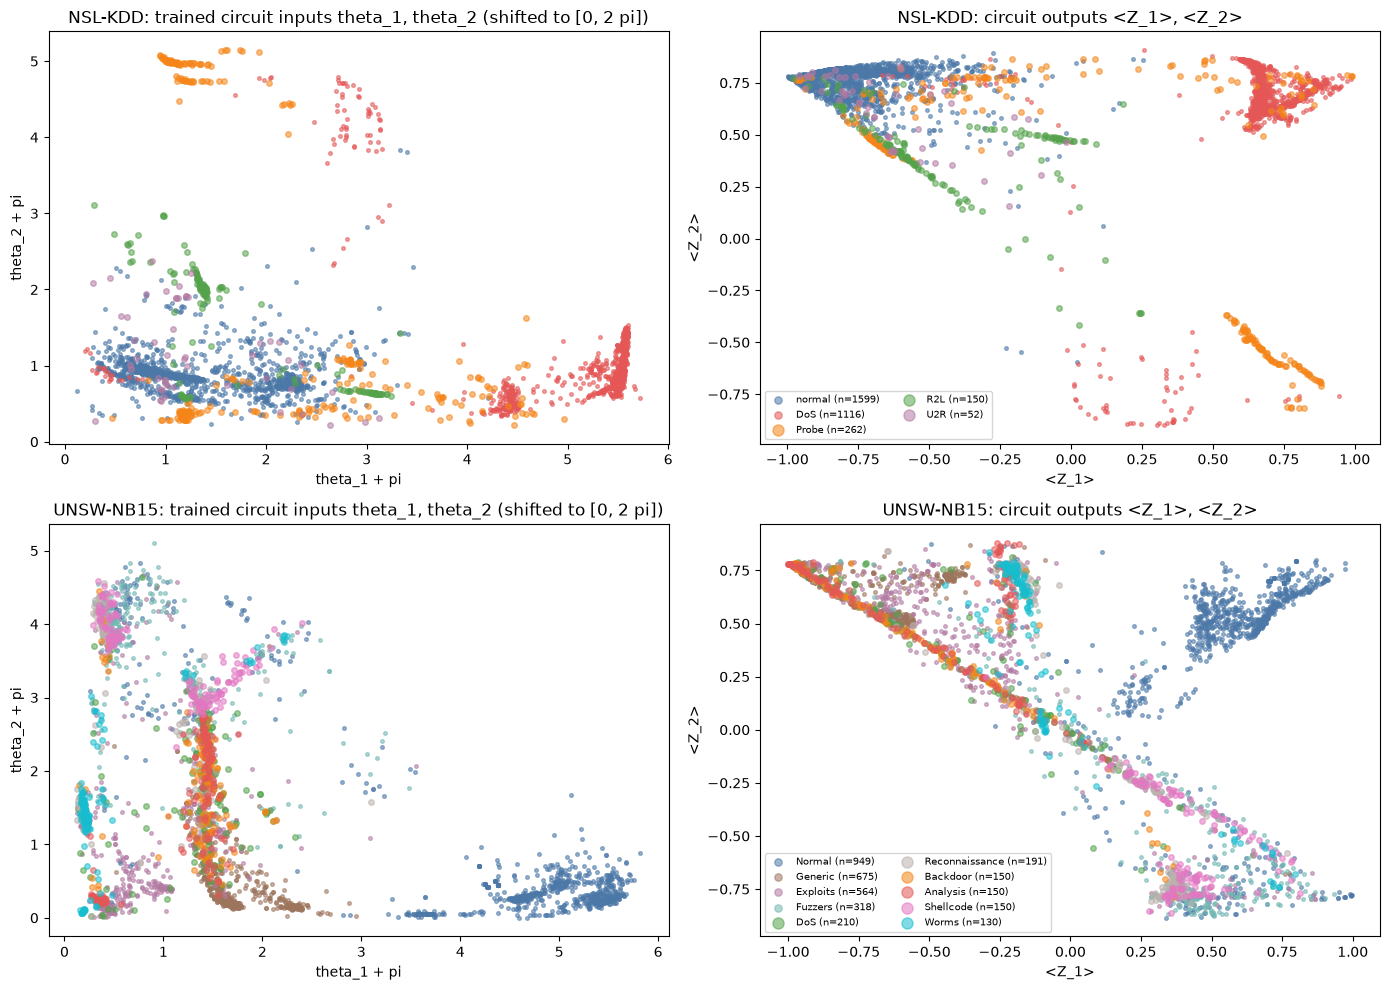

In [21]:
@torch.no_grad()
def circuit_io(model, X):
    model.eval(); h = F.relu(model.conv1(X)).flatten(1); theta = math.pi * torch.tanh(model.angles(h))
    return theta.numpy(), quantum_layer(theta, model.Mcat).numpy()

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for r, (nm, d) in enumerate(D.items()):
    model = RES[(nm, "FedCQIDS", SEEDS[0])]["model"]
    sel = np.random.default_rng(0).choice(len(d["ytr"]), size=min(4000, len(d["ytr"])), replace=False)
    th, ex = circuit_io(model, d["Ttr"][sel]); y = d["ytr"][sel]
    scatter(ax[r, 0], th + math.pi, y, d["classes"], 0, 1, f"{nm}: trained circuit inputs theta_1, theta_2 (shifted to [0, 2 pi])")
    scatter(ax[r, 1], ex, y, d["classes"], 0, 1, f"{nm}: circuit outputs <Z_1>, <Z_2>")
    ax[r, 0].set_xlabel("theta_1 + pi"); ax[r, 0].set_ylabel("theta_2 + pi"); ax[r, 1].set_xlabel("<Z_1>"); ax[r, 1].set_ylabel("<Z_2>")
    ax[r, 1].legend(markerscale=2, fontsize=7, ncol=2, loc="best")
plt.tight_layout(); plt.show()

## 9. The "qubit multiplexing" runtime claim

Section 4.2 states that, for equal input size, the multi-qubit convolution module ran about 12 % faster than the single-qubit module. A state-vector simulator does not save any qubit by reusing one, so only call overhead and state size can differ. The benchmark below times, in PennyLane,
(a) the 4-qubit QNode above (one call per batch) and (b) the same four features processed by a 1-qubit QNode (H, RY, one random rotation, $\langle Z\rangle$) called four times in sequence (one physical qubit reused). The two circuits are not the same model
(the 1-qubit version has no entanglement); the timing only quantifies the simulation cost of the two layouts.

In [22]:
dev1 = qml.device("default.qubit", wires=1)
@qml.qnode(dev1, interface="torch", diff_method="backprop")
def qconv_1q(theta, w):
    qml.Hadamard(wires=0); qml.RY(theta, wires=0); qml.RX(w, wires=0)
    return qml.expval(qml.PauliZ(0))

Bq = 256; REP = 30 if FAST_MODE else 100
th_b = (torch.rand(Bq, N_QUBITS, dtype=torch.float64) * 2 - 1) * math.pi
w4 = torch.tensor(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (1, RL_ROTATIONS))); w1 = torch.tensor(1.234, dtype=torch.float64)
def t_multi(): return torch.stack(qconv_qnode(th_b, w4), -1)
def t_single(): return torch.stack([qconv_1q(th_b[:, i], w1) for i in range(N_QUBITS)], -1)
for f in (t_multi, t_single): f()                                  # warm-up
def bench(f):
    ts = []
    for _ in range(5):
        t0 = time.perf_counter()
        for _ in range(REP // 5): f()
        ts.append((time.perf_counter() - t0) / (REP // 5))
    return np.median(ts) * 1000
tm, ts_ = bench(t_multi), bench(t_single)
reduction = 100 * (ts_ - tm) / ts_
print(f"4-qubit module, one call      : {tm:.2f} ms per batch of {Bq}")
print(f"1-qubit module, 4 sequential  : {ts_:.2f} ms per batch of {Bq}")
print(f"runtime reduction of the multi-qubit layout: {reduction:.1f} %   (paper: about 12 %)")

4-qubit module, one call      : 74.79 ms per batch of 256
1-qubit module, 4 sequential  : 42.81 ms per batch of 256
runtime reduction of the multi-qubit layout: -74.7 %   (paper: about 12 %)


## 10. Paper versus this notebook: verdict per claim

Verdict rule (project convention): a number is *reproduced* when it lies within 2 accuracy points of the paper's value; otherwise *not reached* (ours lower) or *exceeded* (ours higher), with the gap. A directional claim is *reproduced* when the sign is the same.
Claims that depend on the paper's unreported conventions are marked *cannot be checked*.

In [23]:
def verdict(ours, paper, tol=2.0):
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.1f} pts)" if gap > 0 else f"not reached ({gap:.1f} pts)")

def m(ds, name, key):
    return agg(ds, name, lambda s: 100 * s[key])[0]
rows = []
paper5 = {("NSL-KDD", "CIDS"): 92.01, ("NSL-KDD", "CQIDS"): 92.94, ("NSL-KDD", "FedCIDS"): 92.71, ("NSL-KDD", "FedCQIDS"): 93.58,
          ("UNSW-NB15", "CIDS"): 61.04, ("UNSW-NB15", "CQIDS"): 64.26, ("UNSW-NB15", "FedCIDS"): 77.85, ("UNSW-NB15", "FedCQIDS"): 79.82}
for (ds, name), p in paper5.items():
    o = m(ds, name, "max"); rows.append(("Table 5 max accuracy", f"{ds} {name}", p, round(o, 2), verdict(o, p)))
for ds, name, p in [("NSL-KDD", "FedCQIDS", 93.33), ("NSL-KDD", "FedCIDS", 92.22), ("UNSW-NB15", "FedCQIDS", 79.09), ("UNSW-NB15", "FedCIDS", 71.59)]:
    o = m(ds, name, "mean"); rows.append(("mean accuracy over rounds (Sec. 4.2)", f"{ds} {name}", p, round(o, 2), verdict(o, p)))
for ds, p in [("NSL-KDD", 1.11), ("UNSW-NB15", 7.5)]:
    o = m(ds, "FedCQIDS", "mean") - m(ds, "FedCIDS", "mean")
    rows.append(("mean-accuracy gain FedCQIDS - FedCIDS (points)", ds, p, round(o, 2), "reproduced (direction and size)" if o > 0 and abs(o - p) <= 2 else ("direction reproduced, size differs" if o > 0 else "not reproduced (no gain)")))
for ds, p in [("NSL-KDD", -29.7), ("UNSW-NB15", -11.0)]:
    lq, lc = agg(ds, "FedCQIDS", lambda s: s["loss_mean"])[0], agg(ds, "FedCIDS", lambda s: s["loss_mean"])[0]
    o = 100 * (lq - lc) / lc
    rows.append(("mean-loss change FedCQIDS vs FedCIDS (%)", ds, p, round(o, 1), ("direction reproduced (lower loss)" if o < 0 else "not reproduced (loss not lower)") + "; absolute loss scale cannot be checked"))
for ds in SPEC:
    wins = np.mean([np.mean(np.array(RES[(ds, "FedCQIDS", s)]["acc"]) > np.array(RES[(ds, "FedCIDS", s)]["acc"])) for s in SEEDS])
    rows.append(("FedCQIDS above FedCIDS in every round", ds, "100 % of rounds", f"{100*wins:.0f} % of rounds", "reproduced" if wins == 1 else "not reproduced"))
    fl = lambda n: float(np.mean([np.mean(np.abs(np.diff(RES[(ds, n, s)]["acc"]))) for s in SEEDS])) * 100
    rows.append(("FedCQIDS curve smoother (mean |round-to-round change|, points)", ds, "smaller than FedCIDS", f"{fl('FedCQIDS'):.2f} vs {fl('FedCIDS'):.2f}", "reproduced" if fl("FedCQIDS") < fl("FedCIDS") else "not reproduced"))
    for a, b in [("CQIDS", "CIDS"), ("FedCQIDS", "FedCIDS")]:
        o = m(ds, a, "max") - m(ds, b, "max")
        rows.append((f"quantum beats classical, max accuracy ({a} vs {b})", ds, "yes", f"{o:+.2f} pts", "reproduced (direction)" if o > 0 else "not reproduced (no gain)"))
    o = m(ds, "FedCQIDS", "max") - m(ds, "FedCQIDS-control", "max")
    rows.append(("[extra] FedCQIDS vs classical control, max accuracy", ds, "not tested in paper", f"{o:+.2f} pts", "quantum circuit adds accuracy" if o > 1 else ("no evidence that the circuit matters" if abs(o) <= 1 else "control is better")))
for cls, pc, pq in [("Shellcode", 66.7, 71.4), ("Worms", 59.1, 65.9)]:
    rc, rq = recall_last("UNSW-NB15", "FedCIDS", cls)[0], recall_last("UNSW-NB15", "FedCQIDS", cls)[0]
    rows.append((f"Table 6 {cls} recall FedCIDS", "UNSW-NB15", pc, round(rc, 1), verdict(rc, pc, 5.0) + " (tolerance 5 pts, tiny class)"))
    rows.append((f"Table 6 {cls} recall FedCQIDS", "UNSW-NB15", pq, round(rq, 1), verdict(rq, pq, 5.0) + " (tolerance 5 pts, tiny class)"))
    rows.append((f"Table 6 {cls} gain FedCQIDS - FedCIDS (points)", "UNSW-NB15", round(pq - pc, 1), round(rq - rc, 1), "direction reproduced" if rq > rc else "not reproduced (no gain)"))
rows.append(("qubit multiplexing runtime reduction (%)", "PennyLane timing", 12, round(reduction, 1), "direction reproduced, size differs (call overhead only)" if reduction > 0 else "not reproduced"))
rows.append(("absolute loss values 0.0071 / 0.0101 / 0.0606 / 0.0681", "both", "-", "-", "cannot be checked (scale of the paper's loss unknown)"))
rows.append(("Flower / gRPC deployment, NISQ noise", "-", "-", "-", "cannot be checked (not part of the experiment; paper uses ideal simulation)"))
cmp = pd.DataFrame(rows, columns=["claim", "data set / model", "paper", "this notebook", "verdict"])
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 200): display(cmp)
vc = cmp["verdict"].str.split(" ").str[0].str.strip(";").value_counts(); print(vc.to_dict())

,claim,data set / model,paper,this notebook,verdict
0,Table 5 max accuracy,NSL-KDD CIDS,92.01,80.4,not reached (-11.6 pts)
1,Table 5 max accuracy,NSL-KDD CQIDS,92.94,80.28,not reached (-12.7 pts)
2,Table 5 max accuracy,NSL-KDD FedCIDS,92.71,78.59,not reached (-14.1 pts)
3,Table 5 max accuracy,NSL-KDD FedCQIDS,93.58,78.5,not reached (-15.1 pts)
4,Table 5 max accuracy,UNSW-NB15 CIDS,61.04,65.96,exceeded (+4.9 pts)
5,Table 5 max accuracy,UNSW-NB15 CQIDS,64.26,67.3,exceeded (+3.0 pts)
6,Table 5 max accuracy,UNSW-NB15 FedCIDS,77.85,63.91,not reached (-13.9 pts)
7,Table 5 max accuracy,UNSW-NB15 FedCQIDS,79.82,65.73,not reached (-14.1 pts)
8,mean accuracy over rounds (Sec. 4.2),NSL-KDD FedCQIDS,93.33,77.19,not reached (-16.1 pts)
9,mean accuracy over rounds (Sec. 4.2),NSL-KDD FedCIDS,92.22,77.25,not reached (-15.0 pts)


{'not': 18, 'exceeded': 5, 'reproduced': 5, 'direction': 3, 'no': 2, 'cannot': 2}


In [24]:
print("Classical reference points on the identical inputs and the same test rows (test accuracy %, mean over seeds):")
display(base_tab.groupby(["dataset", "model"])["test accuracy %"].mean().round(2).unstack(0))
if NONIID:
    display(pd.DataFrame([dict(dataset=k[0], model=k[1], **{"max acc %": round(100*summarize(v)["max"], 2), "mean acc %": round(100*summarize(v)["mean"], 2), "last acc %": round(100*summarize(v)["last"], 2)}) for k, v in NONIID.items()]))

Classical reference points on the identical inputs and the same test rows (test accuracy %, mean over seeds):


dataset,NSL-KDD,UNSW-NB15
model,,
RandomForest,75.87,72.13
SVC(rbf),75.40,61.04


## Reading the paper critically

* **What the numbers can and cannot show.** The paper's headline gains (about +1 point on NSL-KDD and +2 points on UNSW-NB15 in Table 5, +7.5 points of mean accuracy on UNSW-NB15) come from a single run without variance. In the full run of this notebook (2 seeds, 3,000 training rows) FedCQIDS and FedCIDS differ by
  at most 2 points of maximum accuracy while the seed-to-seed standard deviation of a single model reaches 1.1-1.6 points, so differences of this size are within noise.
* **Absolute accuracy is far from the paper on NSL-KDD and does not reach it on UNSW-NB15.** NSL-KDD 5-class accuracy on the official `KDDTest+` partition stays near 78 % for every network and about 76 % for a RandomForest trained on the same 3,000 rows; the paper reports 92-94 % with the same partition. We could not find a reading of "KDDTrain+ / KDDTest+" that reaches 92 % with these
  models, so the paper's number probably rests on another evaluation protocol. On UNSW-NB15 our federated models reach about 64-66 % maximum accuracy (paper 78-80 %), while a RandomForest on the same inputs reaches 72 %; we trained on about 2 % of the training partition (CPU budget), the paper on all of it, so part of this gap is data volume, not method.
* **"Maximum accuracy" is chosen on the test set.** Table 5 takes the best round on the test partition. That is test-set selection and always flatters a model (our max columns are 0.1-2.6 points above the last-round columns); the mean over rounds and the last round are the honest numbers.
* **The comparison is not parameter-matched, and a classical control matters.** FedCIDS has two convolutions (896 flattened features, 135 k parameters on NSL-KDD); FedCQIDS has one convolution plus a 448->4 bottleneck feeding the circuit (61 k parameters). With a *fixed* random circuit, the quantum module adds four fixed nonlinear features of a trainable projection.
  Replacing the circuit by `cos` (the control) changes maximum accuracy by +0.9 points (NSL-KDD, in favour of the circuit) and -0.3 points (UNSW-NB15), both inside the seed noise: no evidence that the circuit itself matters.
* **Underspecified details.** The paper does not say how 448 values become 4 RY angles, whether the random-layer weights are trained, which random seed or gate pattern was used, which preprocessing produced exactly 42 numbers for NSL-KDD (41 features), how clients obtained their data
  (IID or not; Table 1 says "per client" with the full partitions), or what the "loss" of 0.007 means (it is not a per-flow cross-entropy of a 5- or 10-class problem). Our results therefore test a plausible reading, not necessarily the authors' code. With the random seed 42 of `RandomLayers`, qubit 0 receives no rotation at all (it only
  appears as the target of a CNOT), a detail the paper's description cannot reveal.
* **Test loss rises on NSL-KDD.** Our test cross-entropy increases from about 1.0 to 2.5 over the rounds while accuracy plateaus, i.e. the networks become over-confident on `KDDTest+`, whose 17 new attack types and shifted class mix (R2L is 13 % of the test set but 0.8 % of training) are not covered by training. The paper's smoothly falling loss curves are therefore not a property of the data or method alone; they depend on loss definition and protocol.
* **Federated versus centralised.** In the paper the federated models beat their centralised twins by 15 points on UNSW-NB15 (77.9 vs 61.0), the opposite of what FedAvg normally does. In our runs the centralised CIDS reaches 66.0 % (above the paper's 61.0 %) and the federated model 63.9 %, i.e. federated is at most as good as centralised, as expected. The paper's large federated advantage is not reproduced and is probably an artefact of unequal training budgets (the federated runs see 200 local epochs) in the original experiment.
* **Rare classes.** Table 6 rests on 44 Worms flows and 378 Shellcode flows; one more correct Worms flow moves recall by 2.3 points. Our Shellcode gain (+4.6 points) matches the paper's (+4.7) but the Worms gain does not (-8 points, i.e. 3-4 flows), and both classes are recognised at least as well here (Shellcode 74-79 %, Worms 66-74 %) as in the paper (Shellcode 67-71 %, Worms 59-66 %), partly because we top up the rare classes in the training sample.
* **Qubit multiplexing is a simulation statement.** On a state-vector simulator a reused qubit saves nothing; in our PennyLane timing the single 4-qubit call (which has to expand `RandomLayers` and run four extra gates) is slower than four tiny 1-qubit calls, so the paper's 12 % saving is not reproduced. Timings on a loaded shared CPU are noisy; the claimed suitability for NISQ devices is untested (no noise, no hardware).
* **Reshaping tabular flows into 3 x 2 x 7 images** imposes a spatial structure that the features do not have; the convolution mixes unrelated columns. It works because the following fully connected layers can undo it.
* **Single baseline.** The only comparison is a CNN built by the same authors; no strong tabular baseline (gradient boosting, random forest) is reported. The table above shows that a RandomForest on the same inputs is a strong reference (it beats all networks on UNSW-NB15 here).

## Exercises

1. Set `FAST_MODE = False` and add seeds to `SEEDS`: how large is the seed-to-seed standard deviation of the "max accuracy" of FedCIDS and FedCQIDS compared with their difference?
2. Change `RL_SEED` (the random gate pattern) and the random-layer angles (`build_model`): does FedCQIDS depend on the particular random circuit? Which seeds leave qubit 0 without any rotation?
3. Make the random-layer weights trainable (register them as an `nn.Parameter`, build the observable matrices inside `forward` with autograd, or use the PennyLane QNode through `qml.qnn.TorchLayer`) and compare accuracy and runtime.
4. Replace the IID shards by the Dirichlet shards for all models (`partition="dirichlet"`) and lower `DIRICHLET_ALPHA` to 0.1. Does the gap between FedCIDS and FedCQIDS grow, as the paper's heterogeneity argument suggests?
5. Report macro-F1 instead of accuracy (use `confusion_matrix` stored in `RES`) for the rare UNSW-NB15 classes. Is the quantum model better at *detecting* Worms, or only at being less wrong on the majority classes?